# Unsupervised feature selection and music clustering

This notebook compares unsupervised feature-selection methods on combined global and segment-level audio descriptors. The workflow comprises preprocessing, feature-count search, feature-set overlap analysis, subset selection, confirmation, clustering evaluation, and model export for listening tests.

Feature selection uses development data without genre labels. Candidate subsets are assessed by reference-neighborhood preservation, selection stability, marginal variance, redundancy, and dimensionality. A separate confirmation sample evaluates the selected representation. Reference-neighborhood preservation measures agreement with the input feature space; perceptual recommendation quality requires listening-test evaluation.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import os, json, pickle, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.sparse import csgraph
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors, kneighbors_graph
from sklearn.cluster import KMeans, AgglomerativeClustering, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from threadpoolctl import threadpool_limits


from IPython import get_ipython
from IPython.display import Image, HTML
from io import BytesIO
from itertools import combinations
import matplotlib.lines as mlines
from kneed import KneeLocator
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from sklearn.metrics.cluster import contingency_matrix

import wave

In [2]:
# Configure a notebook backend when available; also explicitly emit PNG output.
# This avoids seeing only a text repr such as <Figure size ...> in some IDEs.
shell = get_ipython()
if shell is not None:
    try:
        shell.run_line_magic('matplotlib', 'inline')
    except (ImportError, RuntimeError):
        plt.switch_backend('Agg')
else:
    plt.switch_backend('Agg')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
latex_column_width_in = 6.5
plt.rcParams.update({'font.family': 'monospace', 'font.size': 9})

def show_table(frame, title=None):
    if isinstance(frame, pd.Series): frame = frame.to_frame()
    if title: display(HTML(f'<h4>{title}</h4>'))
    # Full dataframe, scrollable instead of silently truncating rows/columns.
    display(HTML('<div style="max-height:480px;overflow:auto">' + frame.to_html(float_format=lambda x: f'{x:.4f}') + '</div>'))

def show_figure(fig, name):
    fig.tight_layout()
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=150, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    if 'PLOTS_DIR' in globals():
        fig.savefig(PLOTS_DIR / f'{name}.pdf', bbox_inches='tight', transparent=True, dpi=200)
        fig.savefig(PLOTS_DIR / f'{name}.png', bbox_inches='tight', transparent=True, dpi=PLOT_PNG_DPI)
    plt.close(fig)

In [44]:
SAVED_RUN_ID = '20261026T004854118842Z'  # used only by the optional saved-results loader
FULL_SILHOUETTE_SAMPLE_SIZE = 1000  # None computes exact silhouette on all catalog tracks


SEED = 42
NATIVE_THREADS = 4
DEVELOPMENT_SIZE = 2000
CONFIRMATION_SIZE = 1000
NEIGHBOR_K = 10
FEATURE_SEARCH_MODE = 'coarse_to_fine'  # or 'exhaustive'
FEATURE_COARSE_STEP = 50
FEATURE_REFINEMENT_STEPS = [10, 1]
CORRELATION_THRESHOLDS = [0.70, 0.80, 0.90, 0.95, 0.99]
GROUP_DISTANCE_CUTS = [0.20, 0.30, 0.40, 0.50, 0.70]
PCA_RANKING_VARIANCE = 0.90
LAPLACIAN_NEIGHBORS = 5
STABILITY_REPEATS = 3
STABILITY_FRACTION = 0.80
MIN_NEIGHBOR_OVERLAP = 0.70
MIN_SELECTION_STABILITY = 0.60
RUN_CLUSTERING = True
CLUSTERING_SAMPLE_SIZE = 5000
CLUSTER_COUNTS = list(range(7, 41))
CLUSTER_SEEDS = [0, 42, 123]
SILHOUETTE_SAMPLE_SIZE = 1000
MAX_GINI = 0.40
BIRCH_THRESHOLD = 0.50

# Selection policy: compare both policies inline, then freeze one.
SELECTION_RULE = 'near_best_preservation'  # or 'smallest_qualifying'
MAX_FEATURE_FRACTION = 0.80  # explicit budget; excludes the trivial full-input winner
PRESERVATION_TOLERANCE = 0.02  # absolute overlap: within 2 percentage points of best
FOCUS_METHOD_A = 'variance'
FOCUS_METHOD_B = 'pca_loading'
OVERLAP_FEATURE_COUNT = None  # None: use proposed selection size for matched-count overlap
ELBOW_MIN_POINTS = 4
PLOT_PNG_DPI = 1000  # publication export; lower this for quick previews

# Ranking-test design.
TASKS_PER_CLUSTER = 2
CANDIDATES_PER_TASK = 5
PLANNED_CLIP_SECONDS = 10
AUDIO_SEARCH_DIRS = [Path('../SegmentationOutputFiles'), Path('../UserTests/AudioFiles')]

## Selection criteria

`smallest_meeting_minimum` denotes the lowest tested feature count satisfying both `MIN_NEIGHBOR_OVERLAP` and `MIN_SELECTION_STABILITY`.

Two policies are available through `SELECTION_RULE`:

- `smallest_qualifying`: select the smallest tested subset satisfying the minimum preservation and stability criteria.
- `near_best_preservation`: identify the highest development-neighborhood preservation among stable candidates within `MAX_FEATURE_FRACTION` of the input dimension, then select the smallest subset within `PRESERVATION_TOLERANCE` of that score and above the minimum preservation threshold.

The feature budget controls dimensionality, while the tolerance defines an acceptable preservation difference. These parameters are exploratory settings. Both policy outcomes are displayed for comparison.

Feature-set overlap is evaluated independently using intersections, Jaccard overlap, overlap coefficients, membership tables, and shared or method-specific features. Figures are displayed inline as PNG images and saved as PDF and PNG files.

In [19]:
PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR/'FeatureSelectionforClustering.ipynb').is_file():
    raise RuntimeError('Use music-recommendation-research as the working directory.')
load_dotenv(PROJECT_DIR/'.env')
setting = os.environ.get('FMA_METADATA_DIR')
FMA_METADATA_DIR = Path(setting).expanduser() if setting else None
if FMA_METADATA_DIR is not None:
    if not FMA_METADATA_DIR.is_absolute(): FMA_METADATA_DIR = PROJECT_DIR/FMA_METADATA_DIR
    FMA_METADATA_DIR = FMA_METADATA_DIR.resolve()
print('Project:', PROJECT_DIR)

Project: C:\Users\salom\Documents\PHD\music-recommendation-research


## Manual execution

Run imports, rendering, configuration and project paths. Start a new run to compute experiments, or load saved results and skip the expensive feature-selection/clustering sweep. These are alternative starting cells; do not Run All when reusing results.

After loading saved results, run the elbow-selection cell, then continue at **Fit and save the four final models**. Load the catalog, skip fit/save cells for models already saved, and use **Load saved models and assignments** to continue with analysis.

In [20]:
# Alternative A: run this cell only when starting a new experiment.
if FMA_METADATA_DIR is None: raise RuntimeError('Set FMA_METADATA_DIR in .env.')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = PROJECT_DIR/'outputs'/RUN_ID
RUN_DIR.mkdir(parents=True,exist_ok=False)
PLOTS_DIR = RUN_DIR/'plots';PLOTS_DIR.mkdir()
model_dir = PROJECT_DIR/'models'/RUN_ID/'elbow'
print('New run:',RUN_ID)

New run: 20261026T123759573847Z


In [21]:
# Alternative B: load results without fitting or reading the large feature tables.
RUN_ID = str(SAVED_RUN_ID)
RUN_DIR = (PROJECT_DIR/'outputs'/RUN_ID).resolve()
if RUN_DIR.parent != (PROJECT_DIR/'outputs').resolve(): raise ValueError('Specify a run folder name.')
record = json.loads((RUN_DIR/'selection.json').read_text(encoding='utf8'))
selection_summary,selection_config = record['result'],record['configuration']
selected_features = pd.read_csv(RUN_DIR/'selected_features.csv')['feature'].tolist()
selected_candidate,candidates = selection_summary['candidate'],record['candidates']
if selected_features != candidates[selected_candidate]: raise RuntimeError('Saved feature lists disagree.')
confirmation_passed = bool(selection_summary.get('confirmation_passed',False))
if not confirmation_passed: raise RuntimeError('The saved feature selection did not pass confirmation.')
summary = pd.read_csv(RUN_DIR/'clustering_results.csv',index_col=['model','k'])
clustering_scores = pd.read_csv(RUN_DIR/'clustering_scores_by_seed.csv')
elbow_candidates = pd.read_csv(RUN_DIR/'clustering_elbow_candidates.csv')
historical_rank_shortlist = pd.read_csv(RUN_DIR/'selected_clustering_models.csv')
comparison = pd.read_csv(RUN_DIR/'feature_selection_comparison.csv',index_col=0)
SEED = int(selection_config['SEED'])
PLOTS_DIR = RUN_DIR/'plots';PLOTS_DIR.mkdir(exist_ok=True)
model_dir = PROJECT_DIR/'models'/RUN_ID/'elbow'
shortlist = pd.DataFrame()  # created by the explicit elbow-selection cell
full_model_entries = []
show_table(pd.Series(selection_summary),'Saved feature selection and confirmation')
show_table(elbow_candidates,'Saved elbow candidates: continue with elbow selection')
print('No fitting performed. Skip the research/sweep cells and run the elbow-selection cell next.')

,0
candidate,variance:788
policy,near_best_preservation
confirmation_rule_version,2
n_features,788
input_features,1061
retained_feature_fraction,0.7427
development_knn_overlap,0.9422
stability_jaccard,0.9841
comparator_candidate,variance:848
comparator_n_features,848


,model,elbow_k,status,tested_k
0,Birch,20,candidate_detected,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]"
1,GaussianMixture,18,candidate_detected,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]"
2,KMeans,20,candidate_detected,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]"
3,Ward,19,candidate_detected,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]"


No fitting performed. Skip the research/sweep cells and run the elbow-selection cell next.


In [27]:
tracks = pd.read_csv(FMA_METADATA_DIR / 'tracks.csv', header=[0, 1], index_col=0, low_memory=False)
medium_ids = tracks.index[tracks[('set', 'subset')].isin(['small', 'medium'])]
features = pd.read_csv(FMA_METADATA_DIR / 'features.csv', header=[0, 1, 2], index_col=0)
segments = pd.read_csv(FMA_METADATA_DIR / 'features_segments.csv', header=[0, 1, 2], index_col=0)
for frame in (tracks, features, segments):
    if not frame.index.is_unique:
        raise ValueError('Duplicate track IDs: resolve alignment first.')
missing_ids = medium_ids.difference(features.index).union(medium_ids.difference(segments.index))
if len(missing_ids):
    raise ValueError(f'{len(missing_ids)} medium tracks lack feature rows.')
segments.columns = pd.MultiIndex.from_tuples([(str(a) + '_seg', b, c) for a, b, c in segments.columns])
X_raw = pd.concat([features.loc[medium_ids], segments.loc[medium_ids]], axis=1).sort_index(axis=1)
X_raw.columns = ['-'.join(map(str, col)) for col in X_raw.columns]
if not X_raw.columns.is_unique:
    raise ValueError('Duplicate feature names.')
X_raw = X_raw.astype(float).replace([np.inf, -np.inf], np.nan)
display(pd.Series({'tracks': len(X_raw), 'features': X_raw.shape[1],
    'rows_with_missing': int(X_raw.isna().any(axis=1).sum()),
    'missing_cells': int(X_raw.isna().sum().sum())}))
del tracks, features, segments

tracks               25000
features              1064
rows_with_missing       63
missing_cells        20076
dtype: int64

In [28]:
show_table(X_raw.head(8), 'Combined features: first eight tracks (scroll horizontally)')
show_table(pd.DataFrame({'missing_cells': X_raw.isna().sum()}).query('missing_cells > 0'), 'Columns with missing values')

,missing_cells
auto_correlation_seg-kurtosis-01,2
auto_correlation_seg-max-01,2
auto_correlation_seg-mean-01,2
auto_correlation_seg-median-01,2
auto_correlation_seg-min-01,2
auto_correlation_seg-skew-01,2
auto_correlation_seg-std-01,2
chroma_cens_seg-kurtosis-01,4
chroma_cens_seg-kurtosis-02,4
chroma_cens_seg-kurtosis-03,4


In [29]:
permutation = np.random.default_rng(SEED).permutation(len(X_raw))
if DEVELOPMENT_SIZE + CONFIRMATION_SIZE > len(X_raw):
    raise ValueError('Reduce sample sizes for this dataset.')
development_ids = X_raw.index[permutation[:DEVELOPMENT_SIZE]]
confirmation_ids = X_raw.index[permutation[DEVELOPMENT_SIZE:DEVELOPMENT_SIZE + CONFIRMATION_SIZE]]
assert not len(development_ids.intersection(confirmation_ids))
show_table(pd.DataFrame({'sample': ['development', 'confirmation'], 'tracks': [len(development_ids), len(confirmation_ids)]}), 'Fixed comparison samples')

,sample,tracks
0,development,2000
1,confirmation,1000


In [30]:
nonempty = X_raw.columns[X_raw.loc[development_ids].notna().any(axis=0)].tolist()
imputer = SimpleImputer(strategy='median').fit(X_raw.loc[development_ids, nonempty])
dev_imputed = pd.DataFrame(imputer.transform(X_raw.loc[development_ids, nonempty]),
                           index=development_ids, columns=nonempty)
input_features = dev_imputed.columns[dev_imputed.var(ddof=0) > 0].tolist()
if not input_features:
    raise ValueError('No nonconstant features remain.')
imputer = SimpleImputer(strategy='median').fit(X_raw.loc[development_ids, input_features])
scaler = MinMaxScaler().fit(imputer.transform(X_raw.loc[development_ids, input_features]))

In [31]:
def prepare_features(raw):
    values = raw.loc[:, input_features].replace([np.inf, -np.inf], np.nan)
    return pd.DataFrame(scaler.transform(imputer.transform(values)), index=raw.index, columns=input_features)
X_dev = prepare_features(X_raw.loc[development_ids])
X_confirm = prepare_features(X_raw.loc[confirmation_ids])
print(f'Common input: {len(input_features)} features; dev={len(X_dev)}, confirmation={len(X_confirm)}')
show_table(X_dev.iloc[:8, :12], 'Scaled development data: first 12 features')

Common input: 1061 features; dev=2000, confirmation=1000


,auto_correlation_seg-kurtosis-01,auto_correlation_seg-max-01,auto_correlation_seg-mean-01,auto_correlation_seg-median-01,auto_correlation_seg-min-01,auto_correlation_seg-skew-01,auto_correlation_seg-std-01,chroma_cens-kurtosis-01,chroma_cens-kurtosis-02,chroma_cens-kurtosis-03,chroma_cens-kurtosis-04,chroma_cens-kurtosis-05
track_id,,,,,,,,,,,,
123977,0.0000,0.9926,0.6852,0.7767,0.2106,0.0045,0.5805,0.2258,0.1738,0.0243,0.0481,0.0641
116490,0.0015,0.9978,0.8702,0.7768,0.2941,0.0075,0.1048,0.0824,0.0415,0.0205,0.0541,0.0683
73185,0.0020,0.9785,0.5823,0.7739,0.5231,0.0296,0.0813,0.0616,0.0838,0.0667,0.0412,0.0826
108846,0.0019,0.9740,0.6081,0.7749,0.5732,0.0461,0.0950,0.0745,0.0716,0.0348,0.0518,0.0419
52362,0.0016,0.9691,0.8210,0.7754,0.5810,0.0251,0.0668,0.0654,0.1387,0.0365,0.0533,0.0334
127716,0.0688,0.9725,0.9406,0.7766,0.7383,0.3328,0.0152,0.2247,0.2130,0.0709,0.0488,0.1582
134948,0.0012,0.9625,0.8508,0.7749,0.4467,0.0136,0.1168,0.1318,0.0956,0.0517,0.0293,0.0189
25000,0.0066,0.9616,0.7638,0.7733,0.7945,0.0826,0.0371,0.1499,0.1365,0.0356,0.0559,0.0539


## Unsupervised feature-selection methods

- **Variance ranking:** rank columns by development-set variance and retain the top-k features, with deterministic tie breaking.
- **Spearman filtering:** greedily retain representatives whose absolute correlations with retained features do not exceed the threshold. Fixed column order determines representative priority.
- **Hierarchical feature grouping:** apply average linkage to `1 - abs(Spearman correlation)` and retain the highest-variance member of each group.
- **PCA-loading ranking:** rank original columns by weighted absolute loadings over components covering `PCA_RANKING_VARIANCE`, then retain the top-k features. The retained original columns have no corresponding explained-variance guarantee.
- **Laplacian Score:** rank features by locality preservation on a symmetric weighted k-nearest-neighbor graph; lower scores receive higher priority.
- **Chained filtering:** apply Spearman filtering, a variance threshold, and hierarchical feature grouping sequentially as one combined candidate.

Independent methods use the same preprocessed input. PCA and Laplacian rankings are reused across feature budgets. The complete input representation provides the no-selection baseline.

In [10]:
def abs_spearman(frame):
    corr = frame.corr(method='spearman').abs().fillna(0).to_numpy()
    corr = np.clip((corr + corr.T) / 2, 0, 1)
    np.fill_diagonal(corr, 1)
    return corr

In [11]:
def laplacian_scores(frame):
    values = frame.to_numpy()
    W = kneighbors_graph(values, n_neighbors=min(LAPLACIAN_NEIGHBORS, len(frame)-1),
                        mode='distance', include_self=False, n_jobs=1)
    bandwidth = max(float(np.mean(W.data ** 2)), np.finfo(float).eps)
    W.data = np.exp(-(W.data ** 2) / bandwidth)
    W = W.maximum(W.T)
    degree = np.asarray(W.sum(axis=1)).ravel()
    L = csgraph.laplacian(W, normed=False)
    centered = values - np.average(values, axis=0, weights=degree)
    numerator = np.sum(centered * (L @ centered), axis=0)
    denominator = np.sum(degree[:, None] * centered ** 2, axis=0)
    return np.divide(numerator, denominator, out=np.full(values.shape[1], np.inf),
                     where=denominator > np.finfo(float).eps)

In [12]:
def greedy_representatives(corr, threshold):
    kept = []
    for j in range(len(corr)):
        if not kept or not np.any(corr[j, kept] > threshold):
            kept.append(j)
    return kept

In [13]:
def group_representatives(corr, variances, cut):
    if len(corr) < 2:
        return list(range(len(corr)))
    distance = np.clip(1 - corr, 0, 1)
    np.fill_diagonal(distance, 0)
    tree = linkage(squareform(distance, checks=True), method='average')
    groups = fcluster(tree, t=cut, criterion='distance')
    return [max(np.flatnonzero(groups == g), key=lambda j: (variances[j], -j))
            for g in np.unique(groups)]

In [14]:
def build_candidates(frame):
    names = list(frame.columns)
    candidates, timings, rankings = {}, {}, {}
    def add(method, parameter, positions, elapsed):
        key = f'{method}:{parameter}'
        candidates[key] = [names[j] for j in positions]
        timings[key] = elapsed
    add('baseline', 'all', range(len(names)), 0.0)
    if FEATURE_SEARCH_MODE == 'exhaustive':
        budgets = list(range(1, len(names) + 1))
    elif FEATURE_SEARCH_MODE == 'coarse_to_fine':
        budgets = sorted({1, len(names), *range(FEATURE_COARSE_STEP, len(names), FEATURE_COARSE_STEP)})
    else:
        raise ValueError("FEATURE_SEARCH_MODE must be 'coarse_to_fine' or 'exhaustive'.")
    # Include the exact preservation-budget boundary in the count search.
    budgets = sorted(set(budgets) | {max(1, min(len(names), int(len(names) * MAX_FEATURE_FRACTION)))})
    variances = frame.var(ddof=0).to_numpy()
    start = perf_counter()
    order = np.argsort(-variances, kind='stable')
    elapsed = perf_counter() - start
    rankings['variance'] = [names[j] for j in order]
    for k in budgets:
        add('variance', k, order[:k], elapsed)
    start = perf_counter()
    corr = abs_spearman(frame)
    corr_seconds = perf_counter() - start
    for threshold in CORRELATION_THRESHOLDS:
        start = perf_counter()
        positions = greedy_representatives(corr, threshold)
        add('spearman', threshold, positions, corr_seconds + perf_counter() - start)
    for cut in GROUP_DISTANCE_CUTS:
        start = perf_counter()
        positions = group_representatives(corr, variances, cut)
        add('feature_groups', cut, positions, corr_seconds + perf_counter() - start)
    start = perf_counter()
    with threadpool_limits(limits=NATIVE_THREADS):
        pca = PCA(n_components=PCA_RANKING_VARIANCE, svd_solver='full').fit(frame)
    order = np.argsort(-(np.abs(pca.components_).T @ pca.explained_variance_ratio_), kind='stable')
    elapsed = perf_counter() - start
    rankings['pca_loading'] = [names[j] for j in order]
    for k in budgets:
        add('pca_loading', k, order[:k], elapsed)
    start = perf_counter()
    with threadpool_limits(limits=NATIVE_THREADS):
        order = np.argsort(laplacian_scores(frame), kind='stable')
    elapsed = perf_counter() - start
    rankings['laplacian'] = [names[j] for j in order]
    for k in budgets:
        add('laplacian', k, order[:k], elapsed)
    start = perf_counter()
    filtered = [j for j in greedy_representatives(corr, 0.95) if variances[j] > 0.01]
    if filtered:
        representatives = group_representatives(corr[np.ix_(filtered, filtered)], variances[filtered], 0.30)
        add('chained', 'rho95_var01_group30', [filtered[j] for j in representatives],
            corr_seconds + perf_counter() - start)
    return candidates, timings, rankings

In [15]:
if SELECTION_RULE not in ['near_best_preservation', 'smallest_qualifying']:
    raise ValueError('Unknown SELECTION_RULE.')
if not 0 < MAX_FEATURE_FRACTION <= 1 or not 0 <= PRESERVATION_TOLERANCE < 1:
    raise ValueError('Check the feature budget and preservation tolerance.')
selection_config = {name: globals()[name] for name in [
    'SEED', 'DEVELOPMENT_SIZE', 'CONFIRMATION_SIZE', 'NEIGHBOR_K',
    'FEATURE_SEARCH_MODE', 'FEATURE_COARSE_STEP', 'FEATURE_REFINEMENT_STEPS',
    'CORRELATION_THRESHOLDS', 'GROUP_DISTANCE_CUTS', 'PCA_RANKING_VARIANCE',
    'LAPLACIAN_NEIGHBORS', 'STABILITY_REPEATS', 'STABILITY_FRACTION',
    'MIN_NEIGHBOR_OVERLAP', 'MIN_SELECTION_STABILITY',
    'SELECTION_RULE', 'MAX_FEATURE_FRACTION', 'PRESERVATION_TOLERANCE']}
if not isinstance(FEATURE_COARSE_STEP, int) or FEATURE_COARSE_STEP < 1:
    raise ValueError('FEATURE_COARSE_STEP must be a positive integer.')
if any(not isinstance(step, int) or step < 1 for step in FEATURE_REFINEMENT_STEPS):
    raise ValueError('Refinement steps must be positive integers.')
if STABILITY_REPEATS < 1:
    raise ValueError('STABILITY_REPEATS must be positive.')
candidates, selector_seconds, feature_rankings = build_candidates(X_dev)
print(f'{len(candidates)} initial candidates including the full baseline; mode={FEATURE_SEARCH_MODE}.')

84 initial candidates including the full baseline; mode=coarse_to_fine.


## Feature-selection evaluation

Candidate metrics are computed on development data. Rankings and stability fits are cached across feature counts. Coarse-to-fine search refines around the active policy's qualifying boundary. Because neighborhood preservation can be nonmonotonic, this search identifies the smallest qualifying tested count rather than an exhaustive optimum. Exhaustive mode evaluates every ranked prefix.

Separate tables report method summaries, all candidate metrics, and the outcomes of both selection policies. Trade-off curves show preservation, marginal variance, and stability as functions of feature count.

In [16]:
def neighbor_indices(frame, k=NEIGHBOR_K):
    values = np.asarray(frame)
    if len(values) <= k:
        raise ValueError('Need more rows than neighbors.')
    with threadpool_limits(limits=NATIVE_THREADS):
        nn = NearestNeighbors(n_neighbors=k+1, n_jobs=1).fit(values)
        neighbors = nn.kneighbors(values, return_distance=False)
    return np.array([row[row != i][:k] for i, row in enumerate(neighbors)])

In [17]:
def mean_neighbor_overlap(reference, subset):
    return float(np.mean([len(set(a).intersection(b))/len(a) for a, b in zip(reference, subset)]))

In [18]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0

In [19]:
reference_dev_neighbors = neighbor_indices(X_dev)
reference_corr = abs_spearman(X_dev)
positions = {name: i for i, name in enumerate(X_dev.columns)}
variance_dev = X_dev.var(ddof=0)
# Refit each selector only once per stability sample. Reuse complete rankings
# for every subsequent feature count, including the refinement stages.
repeat_candidates, repeat_rankings = [], []
for repeat in range(STABILITY_REPEATS):
    sample = X_dev.sample(frac=STABILITY_FRACTION, random_state=SEED+repeat+1)
    sample_candidates, _, sample_rankings = build_candidates(sample)
    repeat_candidates.append(sample_candidates)
    repeat_rankings.append(sample_rankings)

In [20]:
def annotate_selection(frame):
    result = frame.copy()
    result['meets_minimum'] = ((result.knn_overlap >= MIN_NEIGHBOR_OVERLAP) &
                               (result.stability_jaccard >= MIN_SELECTION_STABILITY))
    budget = max(1, int(len(input_features) * MAX_FEATURE_FRACTION))
    result['within_budget'] = result.n_features <= budget
    pool = result[result.meets_minimum & result.within_budget]
    best = float(pool.knn_overlap.max()) if len(pool) else np.nan
    target = max(MIN_NEIGHBOR_OVERLAP, best - PRESERVATION_TOLERANCE) if len(pool) else np.nan
    result['within_preservation_band'] = (result.meets_minimum & result.within_budget & (result.knn_overlap >= target))
    result['eligible'] = result.within_preservation_band if SELECTION_RULE == 'near_best_preservation' else result.meets_minimum
    return result, best, target

def choose_candidate(table, flag):
    pool = table[table[flag]].copy()
    if pool.empty: return None
    pool['candidate_name'] = pool.index
    return pool.sort_values(['n_features', 'knn_overlap', 'stability_jaccard', 'candidate_name'],
                            ascending=[True, False, False, True]).index[0]

In [21]:
def evaluate_candidates(keys, stage):
    for key in keys:
        if key in evaluated:
            continue
        selected = candidates[key]
        method = key.split(':')[0]
        idx = [positions[name] for name in selected]
        subcorr = reference_corr[np.ix_(idx, idx)]
        upper = subcorr[np.triu_indices(len(selected), k=1)]
        if method in feature_rankings:
            repeated_subsets = [ranking[method][:len(selected)] for ranking in repeat_rankings]
        else:
            repeated_subsets = [subsets.get(key, []) for subsets in repeat_candidates]
        preservation = mean_neighbor_overlap(reference_dev_neighbors, neighbor_indices(X_dev[selected]))
        stable = float(np.mean([jaccard(selected, subset) for subset in repeated_subsets]))
        rows.append(dict(candidate=key, method=method, n_features=len(selected),
            variance_fraction=float(variance_dev[selected].sum()/variance_dev.sum()),
            mean_abs_spearman=float(upper.mean()) if len(upper) else 0.0,
            knn_overlap=preservation, stability_jaccard=stable,
            segment_features=sum('_seg-' in name for name in selected),
            selector_seconds=selector_seconds[key], search_stage=stage,
            eligible=preservation >= MIN_NEIGHBOR_OVERLAP and stable >= MIN_SELECTION_STABILITY))
        evaluated.add(key)

In [22]:
rows, evaluated = [], set()
evaluate_candidates(list(candidates), 'exhaustive' if FEATURE_SEARCH_MODE == 'exhaustive' else 'coarse')
print('Coarse candidate evaluations:', len(rows))

Coarse candidate evaluations: 84


In [23]:
if FEATURE_SEARCH_MODE == 'coarse_to_fine':
    for step in sorted(set(FEATURE_REFINEMENT_STEPS), reverse=True):
        # Inspect all methods; union their refinement counts and evaluate every
        # ranked method at those same counts for fair matched-budget comparisons.
        current, _, _ = annotate_selection(pd.DataFrame(rows))
        requested_counts = set()
        for method in feature_rankings:
            group = current[current.method == method]
            qualifying = group[group.eligible]
            if qualifying.empty:
                continue
            upper_count = int(qualifying.n_features.min())
            lower_tests = group.loc[group.n_features < upper_count, 'n_features']
            lower_count = int(lower_tests.max()) if len(lower_tests) else 0
            requested_counts.update(range(lower_count + 1, upper_count, step))
        new_keys = []
        for count in sorted(requested_counts):
            for method, ranking in feature_rankings.items():
                key = f'{method}:{count}'
                if key not in candidates:
                    candidates[key] = ranking[:count]
                    selector_seconds[key] = selector_seconds[f'{method}:{len(ranking)}']
                    new_keys.append(key)
        print(f'Refinement step {step}: {len(new_keys)} new candidate subsets.')
        evaluate_candidates(new_keys, f'refine_{step}')

Refinement step 10: 30 new candidate subsets.
Refinement step 1: 54 new candidate subsets.


In [24]:
comparison = pd.DataFrame(rows).set_index('candidate')
comparison['original_features'] = comparison.n_features - comparison.segment_features
comparison, best_budget_preservation, preservation_target = annotate_selection(comparison)
search_summary = comparison.groupby('method').agg(counts_tested=('n_features', 'nunique'),
    minimum_tested=('n_features', 'min'), maximum_tested=('n_features', 'max'),
    best_tested_preservation=('knn_overlap', 'max'))
search_summary['smallest_meeting_minimum'] = comparison[comparison.meets_minimum].groupby('method').n_features.min()
search_summary['smallest_within_preservation_band'] = comparison[comparison.within_preservation_band].groupby('method').n_features.min()
search_summary['best_preservation_within_budget'] = comparison[comparison.within_budget].groupby('method').knn_overlap.max()
show_table(search_summary, 'Method summary: feature counts, not cluster counts')

,counts_tested,minimum_tested,maximum_tested,best_tested_preservation,smallest_meeting_minimum,smallest_within_preservation_band,best_preservation_within_budget
method,,,,,,,
baseline,1,1061,1061,1.0000,1061.0000,NaN,NaN
chained,1,304,304,0.6146,NaN,NaN,0.6146
feature_groups,5,154,698,0.7323,698.0000,NaN,0.7323
laplacian,52,1,1061,1.0000,550.0000,NaN,0.8712
pca_loading,52,1,1061,1.0000,400.0000,835.0000,0.9463
spearman,5,590,1016,0.9267,821.0000,NaN,0.7315
variance,52,1,1061,1.0000,400.0000,788.0000,0.9618


In [25]:
show_table(comparison.sort_values(['n_features', 'knn_overlap'], ascending=[True, False]), 'All candidate metrics')

,method,n_features,variance_fraction,mean_abs_spearman,knn_overlap,stability_jaccard,segment_features,selector_seconds,search_stage,eligible,original_features,meets_minimum,within_budget,within_preservation_band
candidate,,,,,,,,,,,,,,
laplacian:1,laplacian,1,0.0012,0.0000,0.0138,1.0000,0,0.4323,coarse,False,1,False,True,False
pca_loading:1,pca_loading,1,0.0036,0.0000,0.0108,1.0000,1,3.5160,coarse,False,0,False,True,False
variance:1,variance,1,0.0036,0.0000,0.0084,1.0000,1,0.0002,coarse,False,0,False,True,False
pca_loading:50,pca_loading,50,0.1273,0.2082,0.2737,0.8186,41,3.5160,coarse,False,9,False,True,False
variance:50,variance,50,0.1296,0.1750,0.2722,0.9236,41,0.0002,coarse,False,9,False,True,False
laplacian:50,laplacian,50,0.0816,0.3824,0.1697,0.8406,22,0.4323,coarse,False,28,False,True,False
pca_loading:100,pca_loading,100,0.2283,0.1980,0.3588,0.8751,71,3.5160,coarse,False,29,False,True,False
variance:100,variance,100,0.2325,0.1738,0.3537,0.9481,77,0.0002,coarse,False,23,False,True,False
laplacian:100,laplacian,100,0.1718,0.3212,0.2683,0.8693,50,0.4323,coarse,False,50,False,True,False


In [26]:
policy_rows = []
for label, flag in [('smallest_qualifying', 'meets_minimum'), ('near_best_preservation', 'within_preservation_band')]:
    key = choose_candidate(comparison, flag)
    if key is not None:
        policy_rows.append(dict(policy=label, candidate=key, **comparison.loc[key,
            ['n_features', 'knn_overlap', 'stability_jaccard', 'variance_fraction', 'mean_abs_spearman']].to_dict()))
policy_comparison = pd.DataFrame(policy_rows)
show_table(policy_comparison, 'Two possible selections: review the trade-off')
print('Active rule:', SELECTION_RULE, '| feature budget:', int(len(input_features)*MAX_FEATURE_FRACTION),
      '| best within budget:', best_budget_preservation, '| preservation band starts at:', preservation_target)

,policy,candidate,n_features,knn_overlap,stability_jaccard,variance_fraction,mean_abs_spearman
0,smallest_qualifying,variance:400,400,0.7289,0.9737,0.6601,0.1554
1,near_best_preservation,variance:788,788,0.9422,0.9841,0.9456,0.1367


Active rule: near_best_preservation | feature budget: 848 | best within budget: 0.9618000000000001 | preservation band starts at: 0.9418000000000001


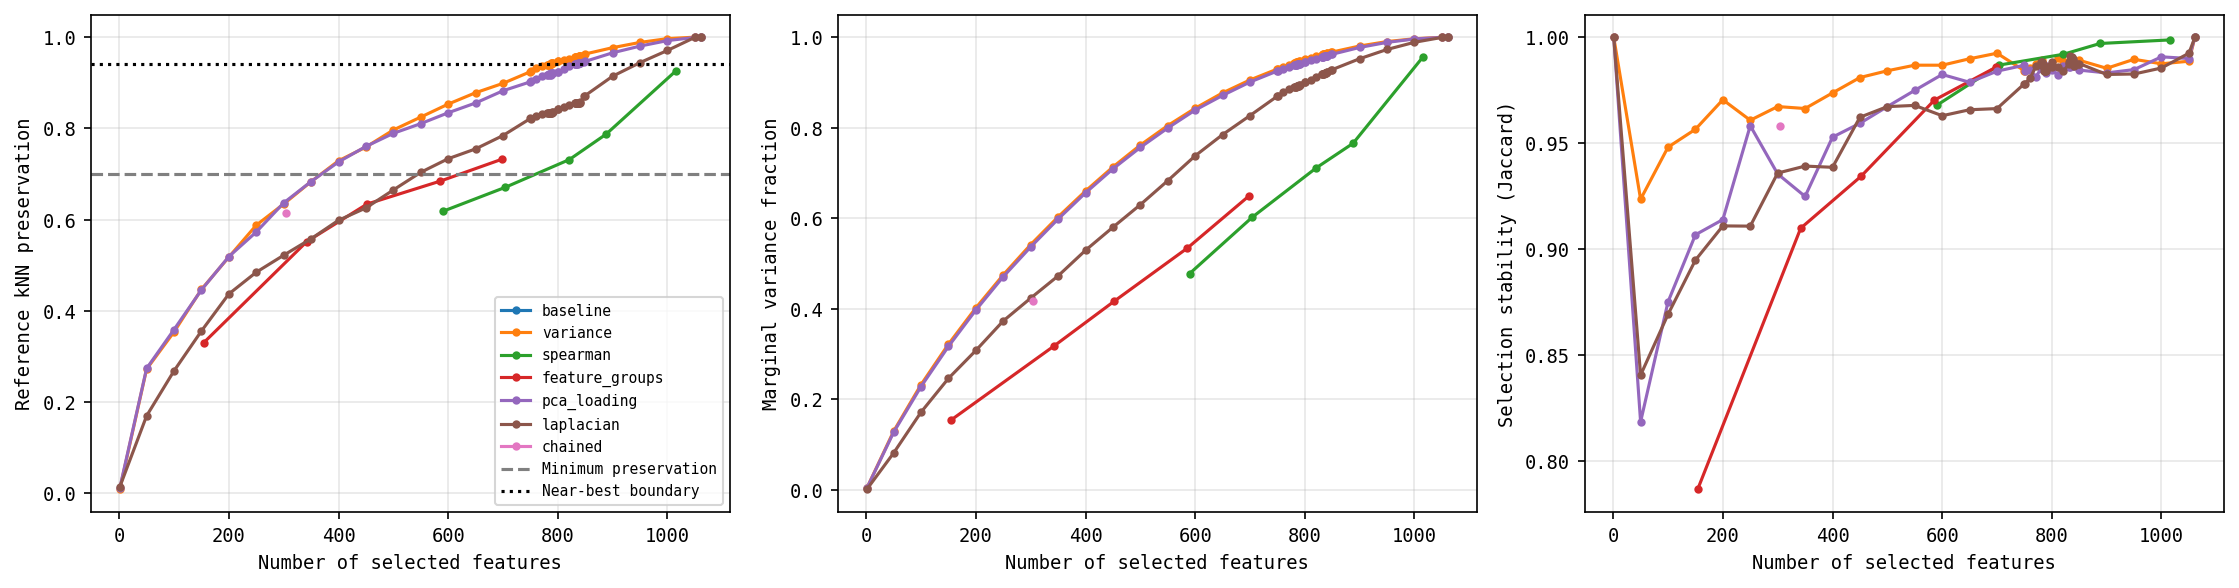

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for method, group in comparison.groupby('method', sort=False):
    ordered = group.sort_values('n_features')
    for ax, column in zip(axes, ['knn_overlap', 'variance_fraction', 'stability_jaccard']):
        ax.plot(ordered.n_features, ordered[column], 'o-', label=method, markersize=3)
axes[0].axhline(MIN_NEIGHBOR_OVERLAP, color='grey', linestyle='--', label='Minimum preservation')
if np.isfinite(preservation_target): axes[0].axhline(preservation_target, color='black', linestyle=':', label='Near-best boundary')
for ax, ylabel in zip(axes, ['Reference kNN preservation', 'Marginal variance fraction', 'Selection stability (Jaccard)']):
    ax.set(xlabel='Number of selected features', ylabel=ylabel)
    ax.grid(alpha=.3)
axes[0].legend(fontsize=7)
show_figure(fig, 'feature_selection_tradeoffs')

## Feature-set overlap and composition

One representative subset is selected per method using the active policy. If a method has no qualifying subset, its strongest stable within-budget candidate is displayed as a diagnostic representative and marked accordingly. The no-selection baseline is excluded from this analysis.

Representative subsets are compared through intersection counts, Jaccard overlap, overlap coefficients, feature membership, and descriptor-family counts. Matched-count comparisons evaluate the three ranked methods with equal subset sizes. `FOCUS_METHOD_A` and `FOCUS_METHOD_B` specify the pair used for detailed shared and method-specific feature lists.

In [28]:
representatives, representative_rows = {}, []
for method, group in comparison[comparison.method != 'baseline'].groupby('method', sort=False):
    chosen = choose_candidate(group, 'eligible')
    qualifies = chosen is not None
    if chosen is None:
        fallback = group[(group.stability_jaccard >= MIN_SELECTION_STABILITY) & group.within_budget]
        if fallback.empty: fallback = group
        chosen = fallback.sort_values(['knn_overlap', 'n_features'], ascending=[False, True]).index[0]
    representatives[method] = chosen
    representative_rows.append(dict(method=method, candidate=chosen, qualifies_for_active_rule=qualifies,
        **comparison.loc[chosen, ['n_features', 'knn_overlap', 'stability_jaccard', 'segment_features', 'original_features']].to_dict()))
representative_table = pd.DataFrame(representative_rows).set_index('method')
show_table(representative_table, 'Representative subsets used for feature overlap')

,candidate,qualifies_for_active_rule,n_features,knn_overlap,stability_jaccard,segment_features,original_features
method,,,,,,,
variance,variance:788,True,788,0.9422,0.9841,404,384
spearman,spearman:0.9,False,821,0.7315,0.9919,419,402
feature_groups,feature_groups:0.2,False,698,0.7323,0.9858,359,339
pca_loading,pca_loading:835,True,835,0.9420,0.9873,418,417
laplacian,laplacian:848,False,848,0.8712,0.9875,422,426
chained,chained:rho95_var01_group30,False,304,0.6146,0.9579,156,148


In [29]:
methods = list(representatives)
feature_sets = {method: set(candidates[key]) for method, key in representatives.items()}
overlap_matrix = pd.DataFrame([[jaccard(feature_sets[a], feature_sets[b]) for b in methods] for a in methods], index=methods, columns=methods)
intersection_counts = pd.DataFrame([[len(feature_sets[a] & feature_sets[b]) for b in methods] for a in methods], index=methods, columns=methods)
pair_rows = []
for a, b in combinations(methods, 2):
    shared = feature_sets[a] & feature_sets[b]
    pair_rows.append(dict(method_a=a, method_b=b, size_a=len(feature_sets[a]), size_b=len(feature_sets[b]),
        shared_features=len(shared), only_a=len(feature_sets[a]-feature_sets[b]), only_b=len(feature_sets[b]-feature_sets[a]),
        jaccard=jaccard(feature_sets[a], feature_sets[b]), overlap_coefficient=len(shared)/min(len(feature_sets[a]), len(feature_sets[b]))))
pairwise_overlap = pd.DataFrame(pair_rows)
show_table(intersection_counts, 'Number of shared features (diagonal = subset size)')
show_table(pairwise_overlap, 'Pairwise intersections, unique counts, and overlap ratios')

,variance,spearman,feature_groups,pca_loading,laplacian,chained
variance,788,594,501,770,714,304
spearman,594,821,626,615,620,282
feature_groups,501,626,698,517,502,257
pca_loading,770,615,517,835,774,304
laplacian,714,620,502,774,848,285
chained,304,282,257,304,285,304


,method_a,method_b,size_a,size_b,shared_features,only_a,only_b,jaccard,overlap_coefficient
0,variance,spearman,788,821,594,194,227,0.5852,0.7538
1,variance,feature_groups,788,698,501,287,197,0.5086,0.7178
2,variance,pca_loading,788,835,770,18,65,0.9027,0.9772
3,variance,laplacian,788,848,714,74,134,0.7744,0.9061
4,variance,chained,788,304,304,484,0,0.3858,1.0000
5,spearman,feature_groups,821,698,626,195,72,0.7010,0.8968
6,spearman,pca_loading,821,835,615,206,220,0.5908,0.7491
7,spearman,laplacian,821,848,620,201,228,0.5910,0.7552
8,spearman,chained,821,304,282,539,22,0.3345,0.9276
9,feature_groups,pca_loading,698,835,517,181,318,0.5089,0.7407


In [30]:
feature_membership = pd.DataFrame({method: pd.Series(True, index=sorted(features), dtype='boolean') for method, features in feature_sets.items()}).fillna(False).astype(bool)
feature_membership['selected_by_methods'] = feature_membership.sum(axis=1)
feature_membership = feature_membership.sort_values('selected_by_methods', ascending=False)
show_table(feature_membership, 'Every selected feature and the methods selecting it')
feature_family_counts = pd.DataFrame({method: pd.Series(sorted(features)).str.replace(r'-(kurtosis|max|mean|median|min|skew|std)-.*$', '', regex=True).value_counts() for method, features in feature_sets.items()}).fillna(0).astype(int)
show_table(feature_family_counts, 'Selected feature families (segment/global families stay separate)')

,variance,spearman,feature_groups,pca_loading,laplacian,chained,selected_by_methods
mfcc-max-03,True,True,True,True,True,True,6
chroma_stft-std-06,True,True,True,True,True,True,6
spectral_contrast-min-03,True,True,True,True,True,True,6
spectral_contrast-min-05,True,True,True,True,True,True,6
chroma_stft-std-12,True,True,True,True,True,True,6
chroma_stft-std-11,True,True,True,True,True,True,6
chroma_stft-std-10,True,True,True,True,True,True,6
chroma_stft-std-09,True,True,True,True,True,True,6
chroma_stft-std-08,True,True,True,True,True,True,6
chroma_stft-std-07,True,True,True,True,True,True,6


,variance,spearman,feature_groups,pca_loading,laplacian,chained
auto_correlation_seg,5,5,5,5,5,2
chroma_cens,65,72,60,73,76,28
chroma_cens_seg,63,72,54,70,74,17
chroma_cqt,52,64,50,59,69,18
chroma_cqt_seg,58,54,43,67,73,24
chroma_stft,46,45,44,57,72,12
chroma_stft_seg,50,54,49,55,66,24
mfcc,127,119,99,127,110,53
mfcc_seg,117,120,107,109,100,47
onset_diff_seg,0,4,4,0,0,0


In [31]:
if FOCUS_METHOD_A not in feature_sets or FOCUS_METHOD_B not in feature_sets:
    raise ValueError('Choose focus methods from: ' + ', '.join(methods))
set_a, set_b = feature_sets[FOCUS_METHOD_A], feature_sets[FOCUS_METHOD_B]
feature_differences = pd.concat([
    pd.DataFrame({'feature': sorted(set_a & set_b), 'membership': 'shared'}),
    pd.DataFrame({'feature': sorted(set_a - set_b), 'membership': 'only ' + FOCUS_METHOD_A}),
    pd.DataFrame({'feature': sorted(set_b - set_a), 'membership': 'only ' + FOCUS_METHOD_B})], ignore_index=True)
show_table(feature_differences, f'Actual features: {FOCUS_METHOD_A} versus {FOCUS_METHOD_B}')

,feature,membership
0,auto_correlation_seg-max-01,shared
1,auto_correlation_seg-mean-01,shared
2,auto_correlation_seg-min-01,shared
3,auto_correlation_seg-skew-01,shared
4,auto_correlation_seg-std-01,shared
5,chroma_cens-kurtosis-01,shared
6,chroma_cens-kurtosis-02,shared
7,chroma_cens-max-01,shared
8,chroma_cens-max-02,shared
9,chroma_cens-max-03,shared


In [32]:
preview_choice = choose_candidate(comparison, 'eligible')
matched_count = int(OVERLAP_FEATURE_COUNT if OVERLAP_FEATURE_COUNT is not None else
    (comparison.loc[preview_choice, 'n_features'] if preview_choice else min(400, len(input_features))))
if not 1 <= matched_count <= len(input_features): raise ValueError('Invalid overlap feature count.')
ranked_methods = list(feature_rankings)
matched_sets = {method: set(ranking[:matched_count]) for method, ranking in feature_rankings.items()}
matched_overlap = pd.DataFrame([[jaccard(matched_sets[a], matched_sets[b]) for b in ranked_methods]
    for a in ranked_methods], index=ranked_methods, columns=ranked_methods)
show_table(matched_overlap, f'Ranked methods at the same count: {matched_count} features each')

,variance,pca_loading,laplacian
variance,1.0000,0.9103,0.7708
pca_loading,0.9103,1.0000,0.8454
laplacian,0.7708,0.8454,1.0000


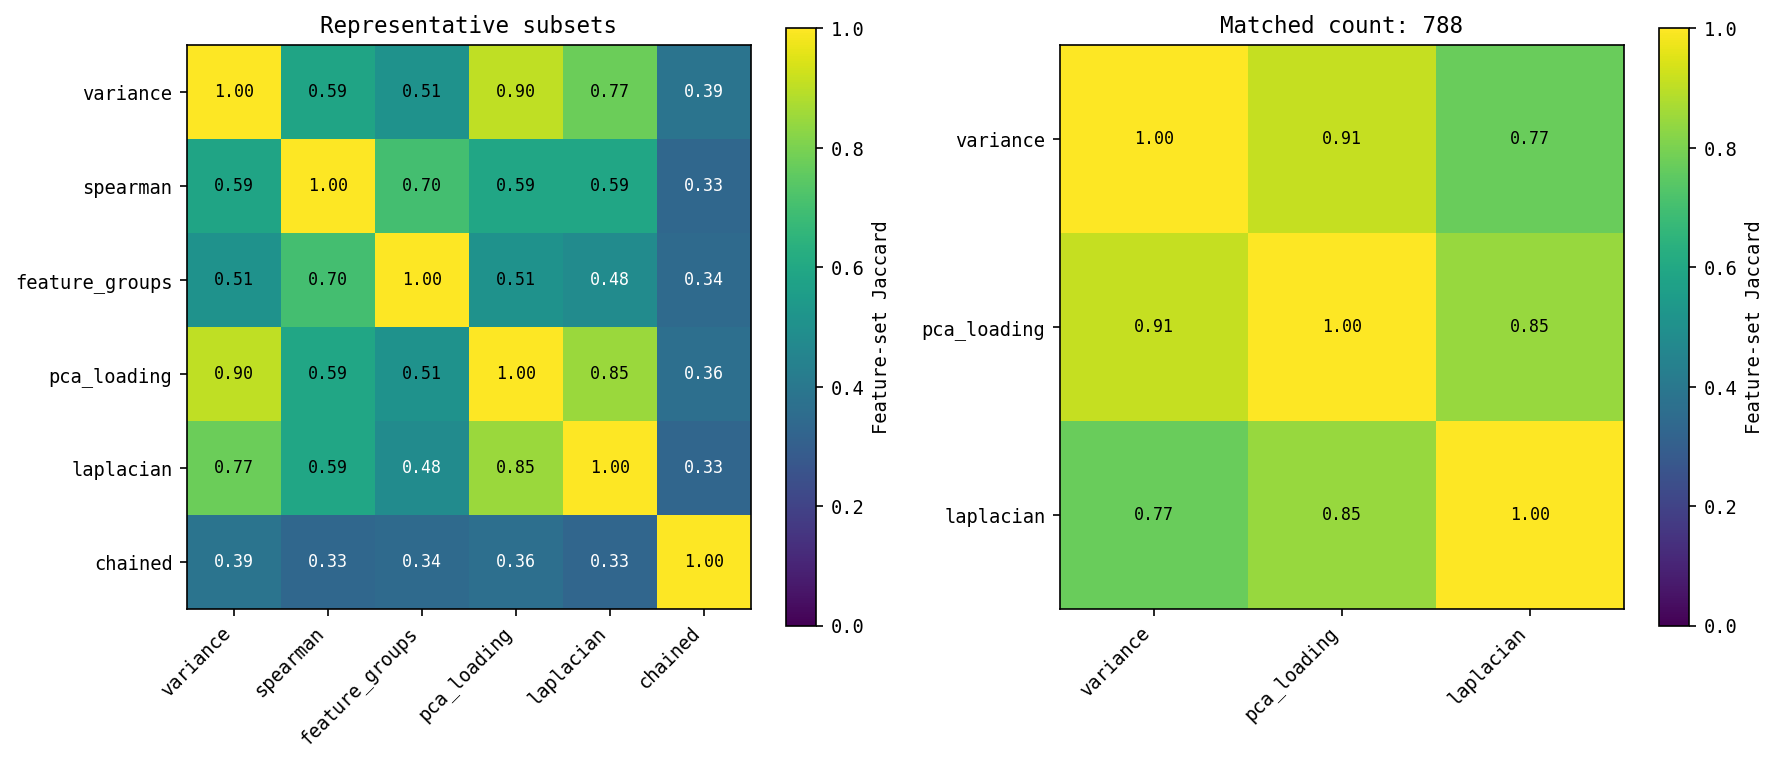

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, matrix, title in [(axes[0], overlap_matrix, 'Representative subsets'), (axes[1], matched_overlap, f'Matched count: {matched_count}')]:
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(title)
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            ax.text(j, i, f'{matrix.iloc[i,j]:.2f}', ha='center', va='center', color='white' if matrix.iloc[i,j]<.5 else 'black', fontsize=8)
    fig.colorbar(image, ax=ax, label='Feature-set Jaccard')
show_figure(fig, 'feature_set_overlap')

## Subset selection and paired confirmation

The selected subset and its comparator are frozen using development results only. Under `near_best_preservation`, the comparator is the highest-preservation stable development candidate within the feature budget. Ties are resolved by feature count, stability, and candidate name.

Both frozen representations are evaluated against the full reference representation on the same confirmation tracks. Confirmation requires the selected subset to meet the absolute preservation floor and remain within the configured preservation tolerance of the frozen comparator. The comparator is not reselected using confirmation results. Under `smallest_qualifying`, only the absolute floor applies.

Results and diagnostics are saved even when confirmation fails, but clustering and export remain blocked. Changes made after inspecting confirmation results constitute further exploration rather than independent validation.

In [34]:
confirmation_passed = False
confirmation_comparison = None
selected_candidate = choose_candidate(comparison, 'eligible')
if selected_candidate is None:
    raise RuntimeError('No candidate satisfies the active rule. Review the trade-off and budget.')
selected_features = list(candidates[selected_candidate])
frozen_policy = SELECTION_RULE
frozen_preservation_floor = float(MIN_NEIGHBOR_OVERLAP)
frozen_preservation_tolerance = float(PRESERVATION_TOLERANCE)
comparator_candidate = None
comparator_features = None
if frozen_policy == 'near_best_preservation':
    comparator_pool = comparison[comparison.meets_minimum & comparison.within_budget].copy()
    if comparator_pool.empty:
        raise RuntimeError('No stable within-budget development comparator is available.')
    comparator_pool['candidate_name'] = comparator_pool.index
    comparator_candidate = comparator_pool.sort_values(
        ['knn_overlap', 'n_features', 'stability_jaccard', 'candidate_name'],
        ascending=[False, True, False, True]).index[0]
    comparator_features = list(candidates[comparator_candidate])
selection_summary = dict(candidate=selected_candidate, policy=frozen_policy,
    confirmation_rule_version=2, n_features=len(selected_features),
    input_features=len(input_features), retained_feature_fraction=len(selected_features)/len(input_features),
    development_knn_overlap=float(comparison.loc[selected_candidate, 'knn_overlap']),
    stability_jaccard=float(comparison.loc[selected_candidate, 'stability_jaccard']),
    comparator_candidate=comparator_candidate,
    comparator_n_features=len(comparator_features) if comparator_features is not None else None,
    comparator_development_knn_overlap=(float(comparison.loc[comparator_candidate, 'knn_overlap'])
        if comparator_candidate is not None else None),
    absolute_preservation_floor=frozen_preservation_floor,
    preservation_tolerance=frozen_preservation_tolerance,
    confirmation_passed=False, reduction_achieved=len(selected_features)<len(input_features))
show_table(pd.Series(selection_summary), 'Frozen subset and development comparator')
show_table(pd.DataFrame({'feature': selected_features}), 'Ordered feature list for clustering and PKL export')

,0
candidate,variance:788
policy,near_best_preservation
confirmation_rule_version,2
n_features,788
input_features,1061
retained_feature_fraction,0.7427
development_knn_overlap,0.9422
stability_jaccard,0.9841
comparator_candidate,variance:848
comparator_n_features,848


,feature
0,chroma_cqt_seg-median-03
1,chroma_cqt_seg-median-04
2,chroma_cqt_seg-median-02
3,chroma_cqt_seg-median-06
4,chroma_stft_seg-median-01
5,chroma_cqt_seg-median-05
6,chroma_stft_seg-median-03
7,chroma_stft_seg-median-05
8,zcr-max-01
9,tempo_seg-std-01


In [35]:
confirmation_passed = False
confirmation_reference_neighbors = neighbor_indices(X_confirm)
confirmation_overlap = mean_neighbor_overlap(confirmation_reference_neighbors,
    neighbor_indices(X_confirm[selected_features]))
comparator_confirmation_overlap = None
confirmation_preservation_gap = None
within_comparator_tolerance = True
required_confirmation_overlap = frozen_preservation_floor
if frozen_policy == 'near_best_preservation':
    comparator_confirmation_overlap = (confirmation_overlap if comparator_features == selected_features else
        mean_neighbor_overlap(confirmation_reference_neighbors, neighbor_indices(X_confirm[comparator_features])))
    # Positive gap means the selected subset preserves fewer reference neighbors.
    confirmation_preservation_gap = comparator_confirmation_overlap - confirmation_overlap
    within_comparator_tolerance = confirmation_preservation_gap <= frozen_preservation_tolerance + 1e-12
    required_confirmation_overlap = max(frozen_preservation_floor,
        comparator_confirmation_overlap - frozen_preservation_tolerance)
meets_absolute_floor = confirmation_overlap >= frozen_preservation_floor
confirmation_passed = bool(meets_absolute_floor and within_comparator_tolerance)
selection_summary.update(confirmation_knn_overlap=confirmation_overlap,
    comparator_confirmation_knn_overlap=comparator_confirmation_overlap,
    confirmation_preservation_gap=confirmation_preservation_gap,
    required_confirmation_overlap=required_confirmation_overlap,
    meets_absolute_floor=bool(meets_absolute_floor),
    within_comparator_tolerance=bool(within_comparator_tolerance),
    confirmation_passed=confirmation_passed)
confirmation_rows = [dict(role='selected', candidate=selected_candidate,
    n_features=len(selected_features), development_preservation=selection_summary['development_knn_overlap'],
    confirmation_preservation=confirmation_overlap)]
if comparator_candidate is not None:
    confirmation_rows.append(dict(role='frozen development comparator', candidate=comparator_candidate,
        n_features=len(comparator_features),
        development_preservation=selection_summary['comparator_development_knn_overlap'],
        confirmation_preservation=comparator_confirmation_overlap))
confirmation_comparison = pd.DataFrame(confirmation_rows)
show_table(confirmation_comparison, 'Paired confirmation on identical tracks')
show_table(pd.Series(selection_summary), 'Confirmation criteria and outcome')

,role,candidate,n_features,development_preservation,confirmation_preservation
0,selected,variance:788,788,0.9422,0.9392
1,frozen development comparator,variance:848,848,0.9618,0.9581


,0
candidate,variance:788
policy,near_best_preservation
confirmation_rule_version,2
n_features,788
input_features,1061
retained_feature_fraction,0.7427
development_knn_overlap,0.9422
stability_jaccard,0.9841
comparator_candidate,variance:848
comparator_n_features,848


In [36]:
comparison.to_csv(RUN_DIR / 'feature_selection_comparison.csv')
search_summary.to_csv(RUN_DIR / 'feature_count_search.csv')
policy_comparison.to_csv(RUN_DIR / 'selection_policy_comparison.csv', index=False)
representative_table.to_csv(RUN_DIR / 'method_representatives.csv')
overlap_matrix.to_csv(RUN_DIR / 'feature_selection_overlap.csv')
intersection_counts.to_csv(RUN_DIR / 'feature_intersection_counts.csv')
pairwise_overlap.to_csv(RUN_DIR / 'pairwise_feature_overlap.csv', index=False)
feature_membership.to_csv(RUN_DIR / 'feature_membership.csv')
feature_family_counts.to_csv(RUN_DIR / 'feature_family_counts.csv')
feature_differences.to_csv(RUN_DIR / 'focused_feature_differences.csv', index=False)
matched_overlap.to_csv(RUN_DIR / 'matched_count_overlap.csv')
pd.Series(selected_features, name='feature').to_csv(RUN_DIR / 'selected_features.csv', index=False)
pd.Series(development_ids, name='track_id').to_csv(RUN_DIR / 'development_tracks.csv', index=False)
pd.Series(confirmation_ids, name='track_id').to_csv(RUN_DIR / 'confirmation_tracks.csv', index=False)
# Preserve an earlier outcome before updating the same run's selection record.
selection_path = RUN_DIR / 'selection.json'
selection_record = dict(configuration=selection_config, result=selection_summary, candidates=candidates)
if selection_path.exists():
    previous_record = json.loads(selection_path.read_text(encoding='utf8'))
    if previous_record != selection_record:
        history_dir = RUN_DIR / 'selection_history'
        history_dir.mkdir(exist_ok=True)
        history_name = 'selection_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + '.json'
        (history_dir / history_name).write_text(json.dumps(previous_record, indent=2), encoding='utf8')
selection_path.write_text(json.dumps(selection_record, indent=2), encoding='utf8')
confirmation_comparison.to_csv(RUN_DIR / 'confirmation_comparison.csv', index=False)
if not confirmation_passed:
    raise RuntimeError(
        f"Confirmation failed: selected preservation={confirmation_overlap:.4f}, "
        f"required={required_confirmation_overlap:.4f}; "
        f"absolute floor passed={meets_absolute_floor}, "
        f"comparator tolerance passed={within_comparator_tolerance}. "
        'Results saved; inspect the paired confirmation table before proceeding.')

## Screening curves and elbow selection

The k sweep is an optional expensive cell. Saved curves can be loaded instead. Kneed selects k from mean distortion, and other internal metrics remain diagnostics and balance checks. If no elbow is detected, the model remains unresolved; no ranking-based k is substituted. A balance failure at the elbow is flagged and rechecked after the full-catalog fit.

In [35]:
def make_cluster_model(name, k, seed):
    if name == 'KMeans': return KMeans(n_clusters=k, n_init=20, random_state=seed)
    if name == 'Ward': return AgglomerativeClustering(n_clusters=k, linkage='ward')
    if name == 'GaussianMixture':
        return GaussianMixture(n_components=k, n_init=3, reg_covar=1e-6, random_state=seed)
    if name == 'Birch': return Birch(n_clusters=k, threshold=BIRCH_THRESHOLD)
    raise ValueError(name)

In [36]:
def gini_counts(labels):
    counts = np.sort(np.unique(labels, return_counts=True)[1].astype(float))
    n = len(counts)
    return float(2*np.dot(np.arange(1, n+1), counts)/(n*counts.sum()) - (n+1)/n)

In [37]:
def clustering_metrics(values, labels, silhouette_sample_size=SILHOUETTE_SAMPLE_SIZE):
    unique = np.unique(labels)
    if not 1 < len(unique) < len(values):
        raise ValueError('Metrics require between 2 and n_samples-1 occupied clusters.')
    wcss = sum(float(np.sum((values[labels==label] - values[labels==label].mean(axis=0))**2)) for label in unique)
    return dict(silhouette=float(silhouette_score(values, labels,
        sample_size=None if silhouette_sample_size is None else min(silhouette_sample_size, len(values)), random_state=SEED)),
        calinski_harabasz=float(calinski_harabasz_score(values, labels)),
        davies_bouldin=float(davies_bouldin_score(values, labels)),
        wcss=wcss, distortion=wcss/len(values), gini=gini_counts(labels), occupied_clusters=len(unique))

In [40]:
clustering_scores = pd.DataFrame()
shortlist = pd.DataFrame()
if RUN_CLUSTERING:
    if not confirmation_passed: raise RuntimeError('Confirmation has not passed.')
    screen_ids = X_raw.sample(n=min(CLUSTERING_SAMPLE_SIZE, len(X_raw)), random_state=SEED).index
    pd.Series(screen_ids, name='track_id').to_csv(RUN_DIR / 'clustering_evaluation_tracks.csv', index=False)
    X_screen = prepare_features(X_raw.loc[screen_ids])[selected_features].to_numpy()
    rows = []
    for name in ['KMeans', 'Ward', 'GaussianMixture', 'Birch']:
        for k in CLUSTER_COUNTS:
            seeds = CLUSTER_SEEDS if name in ['KMeans', 'GaussianMixture'] else [SEED]
            for seed in seeds:
                if k >= len(X_screen): continue
                model = make_cluster_model(name, k, seed)
                start = perf_counter()
                with threadpool_limits(limits=NATIVE_THREADS):
                    labels = model.fit_predict(X_screen)
                    scores = clustering_metrics(X_screen, labels)
                rows.append(dict(model=name, k=k, seed=seed, **scores, seconds=perf_counter()-start))
                print(f"{name} k={k} seed={seed} | Sil={scores['silhouette']:.4f} | "
                      f"CH={scores['calinski_harabasz']:.2f} | DB={scores['davies_bouldin']:.4f} | "
                      f"Dist={scores['distortion']:.4f} | WCSS={scores['wcss']:.2f} | Gini={scores['gini']:.4f}")
    clustering_scores = pd.DataFrame(rows)
    clustering_scores.to_csv(RUN_DIR / 'clustering_scores_by_seed.csv', index=False)

else:
    print('Clustering skipped: RUN_CLUSTERING=False.')

KMeans k=7 seed=0 | Sil=0.0319 | CH=195.64 | DB=3.7150 | Dist=10.9643 | WCSS=54821.65 | Gini=0.1389
KMeans k=7 seed=42 | Sil=0.0321 | CH=195.74 | DB=3.7069 | Dist=10.9633 | WCSS=54816.63 | Gini=0.1347
KMeans k=7 seed=123 | Sil=0.0320 | CH=195.73 | DB=3.7092 | Dist=10.9635 | WCSS=54817.34 | Gini=0.1334
KMeans k=8 seed=0 | Sil=0.0317 | CH=177.36 | DB=3.6157 | Dist=10.8449 | WCSS=54224.36 | Gini=0.1862
KMeans k=8 seed=42 | Sil=0.0301 | CH=177.36 | DB=3.6213 | Dist=10.8449 | WCSS=54224.36 | Gini=0.1899
KMeans k=8 seed=123 | Sil=0.0313 | CH=177.40 | DB=3.6159 | Dist=10.8444 | WCSS=54221.99 | Gini=0.1872
KMeans k=9 seed=0 | Sil=0.0246 | CH=161.91 | DB=3.5919 | Dist=10.7518 | WCSS=53758.95 | Gini=0.1799
KMeans k=9 seed=42 | Sil=0.0210 | CH=161.71 | DB=3.6609 | Dist=10.7545 | WCSS=53772.35 | Gini=0.1839
KMeans k=9 seed=123 | Sil=0.0172 | CH=161.81 | DB=3.6368 | Dist=10.7532 | WCSS=53765.87 | Gini=0.1643
KMeans k=10 seed=0 | Sil=0.0206 | CH=149.52 | DB=3.5825 | Dist=10.6658 | WCSS=53328.80 | Gi

In [41]:
if not clustering_scores.empty:
    show_table(clustering_scores.sort_values(['model', 'k', 'seed']), 'Every clustering run: all metrics')

,model,k,seed,silhouette,calinski_harabasz,davies_bouldin,wcss,distortion,gini,occupied_clusters,seconds
238,Birch,7,42,0.0029,143.1256,4.6055,57773.7493,11.5547,0.1510,7,16.8293
239,Birch,8,42,-0.0111,130.7968,4.4010,57216.3513,11.4433,0.1155,8,16.0647
240,Birch,9,42,-0.0087,121.1739,4.2644,56698.0126,11.3396,0.1569,9,16.7094
241,Birch,10,42,-0.0082,112.6946,4.0914,56272.5635,11.2545,0.2334,10,16.1814
242,Birch,11,42,-0.0125,105.7042,4.2946,55872.4068,11.1745,0.1999,11,17.0915
243,Birch,12,42,-0.0161,99.6119,4.2552,55515.1429,11.1030,0.2474,12,16.0234
244,Birch,13,42,-0.0139,94.4499,4.2266,55171.4829,11.0343,0.2953,13,17.1187
245,Birch,14,42,-0.0121,89.7456,4.2796,54870.8940,10.9742,0.2893,14,16.6966
246,Birch,15,42,-0.0116,85.5510,4.1733,54593.5110,10.9187,0.3201,15,17.0876
247,Birch,16,42,-0.0109,81.7658,4.0917,54338.4616,10.8677,0.3448,16,17.6284


In [42]:
summary = pd.DataFrame()
if not clustering_scores.empty:
    grouped = clustering_scores.groupby(['model', 'k'])
    metric_names = ['silhouette', 'calinski_harabasz', 'davies_bouldin', 'wcss', 'distortion', 'gini']
    summary = grouped[metric_names].mean()
    summary['silhouette_std'] = grouped.silhouette.std().fillna(0)
    summary['max_gini'] = grouped.gini.max()
    summary['min_occupied_clusters'] = grouped.occupied_clusters.min()
    summary['eligible'] = ((summary.max_gini <= MAX_GINI) &
        (summary.min_occupied_clusters == summary.index.get_level_values('k')))
    summary.to_csv(RUN_DIR / 'clustering_results.csv')
    show_table(summary, 'Mean metrics across seeds, variation, and balance eligibility')

In [22]:
elbow_rows = []
if not summary.empty:
    for name, group in summary.reset_index().groupby('model'):
        group = group.sort_values('k')
        x, y = group.k.to_numpy(), group.distortion.to_numpy()
        knee, status = None, 'no_elbow_detected'
        if len(x) < ELBOW_MIN_POINTS: status = 'insufficient_k_values'
        elif np.ptp(y) <= np.finfo(float).eps: status = 'flat_curve'
        elif np.any(np.diff(y) > 1e-8): status = 'non_monotonic_distortion'
        else:
            locator = KneeLocator(x, y, curve='convex', direction='decreasing', S=1.0)
            knee = int(locator.elbow) if locator.elbow is not None else None
            if knee is not None: status = 'candidate_detected'
        elbow_rows.append(dict(model=name, elbow_k=knee, status=status, tested_k=list(map(int, x))))
elbow_candidates = pd.DataFrame(elbow_rows, columns=['model', 'elbow_k', 'status', 'tested_k'])
show_table(elbow_candidates, 'Kneed candidates from mean distortion; no invented elbow when k is sparse')
if not elbow_candidates.empty: elbow_candidates.to_csv(RUN_DIR / 'clustering_elbow_candidates.csv', index=False)

,model,elbow_k,status,tested_k
0,Birch,20,candidate_detected,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]"
1,GaussianMixture,18,candidate_detected,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]"
2,KMeans,20,candidate_detected,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]"
3,Ward,19,candidate_detected,"[7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]"


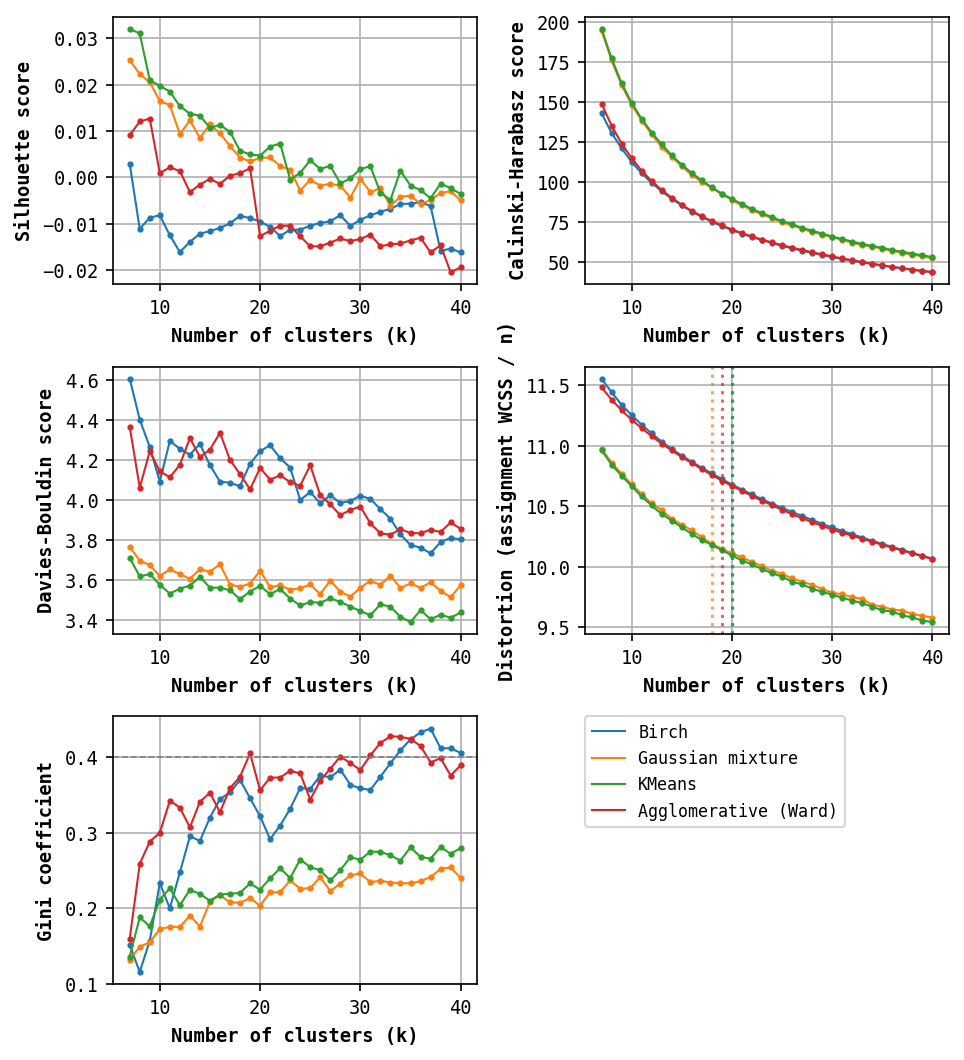

In [23]:
if not summary.empty:
    scores_df_renamed = summary.reset_index().rename(columns={
        'silhouette': 'Silhouette score', 'calinski_harabasz': 'Calinski-Harabasz score',
        'davies_bouldin': 'Davies-Bouldin score', 'distortion': 'Distortion (assignment WCSS / n)',
        'gini': 'Gini coefficient'})
    metrics_to_plot = ['Silhouette score', 'Calinski-Harabasz score', 'Davies-Bouldin score',
                       'Distortion (assignment WCSS / n)', 'Gini coefficient']
    fig, axes = plt.subplots(3, 2, figsize=(latex_column_width_in, latex_column_width_in * 1.1))
    axes = axes.flatten()
    handles = []
    names = list(scores_df_renamed.model.unique())
    colors = {name: plt.rcParams['axes.prop_cycle'].by_key()['color'][i % 10] for i, name in enumerate(names)}
    labels = {'Ward': 'Agglomerative (Ward)', 'GaussianMixture': 'Gaussian mixture'}
    for i, metric in enumerate(metrics_to_plot):
        ax = axes[i]
        for name in names:
            subset = scores_df_renamed[scores_df_renamed.model == name].sort_values('k')
            line, = ax.plot(subset.k, subset[metric], linewidth=1, marker='o', markersize=2,
                            color=colors[name], label=labels.get(name, name))
            if i == 0: handles.append(mlines.Line2D([], [], color=line.get_color(), linewidth=1, label=labels.get(name, name)))
            if metric.startswith('Distortion') and not elbow_candidates.empty:
                found = elbow_candidates[elbow_candidates.model == name].elbow_k.dropna()
                if len(found): ax.axvline(float(found.iloc[0]), color=colors[name], linestyle=':', alpha=.7)
        if metric == 'Gini coefficient': ax.axhline(MAX_GINI, color='grey', linestyle='--', linewidth=.8)
        ax.set_xlabel('Number of clusters (k)', fontname='monospace', fontsize=9, fontweight='bold')
        ax.set_ylabel(metric, fontname='monospace', fontsize=9, fontweight='bold')
        ax.tick_params(axis='both', labelsize=9)
        ax.grid(True)
    axes[-1].axis('off')
    axes[-1].legend(handles=handles, loc='upper left', fontsize=8, borderaxespad=0.)
    show_figure(fig, 'clustering_metrics')

In [24]:
# Select k from Kneed, never from the metric ranking.
selected_rows,unresolved_rows = [],[]
for name in ['KMeans','GaussianMixture','Ward','Birch']:
    found = elbow_candidates[elbow_candidates.model==name]
    if found.empty or pd.isna(found.iloc[0].elbow_k):
        unresolved_rows.append(dict(model=name,status='no_detected_elbow'))
        continue
    k = int(found.iloc[0].elbow_k)
    if (name,k) not in summary.index:
        raise RuntimeError(f'Elbow k={k} for {name} is absent from the saved curve.')
    metrics = summary.loc[(name,k)].to_dict()
    selected_rows.append(dict(model=name,k=k,**metrics,selection_criterion='kneed_distortion_elbow',
        screening_balance_passed=bool(metrics['eligible']),elbow_status=found.iloc[0].status))
shortlist = pd.DataFrame(selected_rows)
unresolved_elbows = pd.DataFrame(unresolved_rows)
show_table(shortlist,'Elbow-selected configurations; balance failures remain explicitly flagged')
if not unresolved_elbows.empty: show_table(unresolved_elbows,'No automatic alternative k: inspect these curves')
shortlist.to_csv(RUN_DIR/'elbow_selected_models.csv',index=False)
full_model_entries = []
print('Historical rank-selected models and files are unchanged.')

,model,k,silhouette,calinski_harabasz,davies_bouldin,wcss,distortion,gini,silhouette_std,max_gini,min_occupied_clusters,eligible,selection_criterion,screening_balance_passed,elbow_status
0,KMeans,20,0.0047,89.5473,3.5706,50468.1109,10.0936,0.2246,0.0032,0.2343,20,True,kneed_distortion_elbow,True,candidate_detected
1,GaussianMixture,18,0.0043,96.4800,3.5655,50940.0428,10.1880,0.2073,0.0039,0.2137,18,True,kneed_distortion_elbow,True,candidate_detected
2,Ward,19,0.0019,73.0920,4.0527,53562.5884,10.7125,0.4055,0.0000,0.4055,19,False,kneed_distortion_elbow,False,candidate_detected
3,Birch,20,-0.0095,70.2546,4.2431,53397.6582,10.6795,0.3219,0.0000,0.3219,20,True,kneed_distortion_elbow,True,candidate_detected


Historical rank-selected models and files are unchanged.


## Fit and save the four final models

Each model has its own fit and save cells. Run a fit cell only to recompute that model. If the PKLs already exist, skip fitting and use the loading cells below. Models use all 25,000 catalog tracks and the selected features; k is taken from the elbow shortlist.

Files in `simple_elbow/` are ordinary sklearn model PKLs, not model bundles. Assignment CSVs retain song membership, including for Ward, which has no `predict` method. Shared preprocessing is saved once. The earlier bundles remain unchanged.

In [48]:
model_dir = PROJECT_DIR/'models'/RUN_ID/'simple_elbow'
model_dir.mkdir(parents=True,exist_ok=True)
selected_k = pd.read_csv(RUN_DIR/'elbow_selected_models.csv').set_index('model')['k'].astype(int)
display(selected_k.to_frame('elbow_k'))

,elbow_k
model,
KMeans,20
GaussianMixture,18
Ward,19
Birch,20


### Catalog features

Choose one preparation cell, or skip both if `X_catalog` and `catalog_track_ids` are already ready. Use the raw-table cell for a newly computed representation. For the saved run, load the identical selected/scaled catalog from its trusted K-Means bundle; this does not select or fit that old model.

In [49]:
# Option A: newly computed features and preprocessing already in memory.
X_catalog = prepare_features(X_raw)[selected_features].to_numpy()
catalog_track_ids = X_raw.index.to_numpy(dtype=np.int64)
print(X_catalog.shape)

(25000, 788)


In [50]:
with (PROJECT_DIR/'models'/SAVED_RUN_ID/'elbow'/'KMeans_k20.pkl').open('rb') as f:
    catalog_data = pickle.load(f)
assert catalog_data['selected_features'] == list(selected_features), 'The saved bundle uses a different feature list.'
X_catalog = catalog_data['selected_scaled_features']
catalog_track_ids = catalog_data['track_ids']
selected_features = catalog_data['selected_features']
imputer, scaler = catalog_data['imputer'], catalog_data['scaler']
input_features = catalog_data['input_features']
print(X_catalog.shape)

(25000, 788)


### KMeans

In [51]:
print('Fitting KMeans on', X_catalog.shape, flush=True)
kmeans = KMeans(n_clusters=int(selected_k['KMeans']), n_init=20, random_state=SEED)
with threadpool_limits(limits=NATIVE_THREADS):
    kmeans_labels = kmeans.fit_predict(X_catalog)
print('KMeans finished', flush=True)

Fitting KMeans on (25000, 788)
KMeans finished


In [52]:
with (model_dir/f'KMeans_k{selected_k["KMeans"]}.pkl').open('wb') as f:
    pickle.dump(kmeans,f,pickle.HIGHEST_PROTOCOL)
pd.DataFrame({'track_id':catalog_track_ids,'cluster':kmeans_labels}).to_csv(
    model_dir/f'KMeans_k{selected_k["KMeans"]}_assignments.csv',index=False)

### GaussianMixture

In [53]:
print('Fitting GaussianMixture on', X_catalog.shape, flush=True)
gmm = GaussianMixture(n_components=int(selected_k['GaussianMixture']), n_init=3, reg_covar=1e-6, random_state=SEED, verbose=2, verbose_interval=5)
with threadpool_limits(limits=NATIVE_THREADS):
    gmm_labels = gmm.fit_predict(X_catalog)
print('GaussianMixture finished', flush=True)

Fitting GaussianMixture on (25000, 788)
Initialization 0
  Iteration 5	 time lapse 1815.18154s	 ll change 0.01746
Initialization converged: True	 time lapse 3235.80024s	 ll 1632.06031
Initialization 1
  Iteration 5	 time lapse 2454.36365s	 ll change 0.00048
Initialization converged: True	 time lapse 2454.36887s	 ll 1622.19247
Initialization 2
  Iteration 5	 time lapse 2161.76292s	 ll change 0.01246
  Iteration 10	 time lapse 2110.65039s	 ll change 0.00041
Initialization converged: True	 time lapse 4272.41331s	 ll 1633.37086
GaussianMixture finished


In [54]:
with (model_dir/f'GaussianMixture_k{selected_k["GaussianMixture"]}.pkl').open('wb') as f:
    pickle.dump(gmm,f,pickle.HIGHEST_PROTOCOL)
pd.DataFrame({'track_id':catalog_track_ids,'cluster':gmm_labels}).to_csv(
    model_dir/f'GaussianMixture_k{selected_k["GaussianMixture"]}_assignments.csv',index=False)

### Ward

In [55]:
print('Fitting Ward on', X_catalog.shape, flush=True)
ward = AgglomerativeClustering(n_clusters=int(selected_k['Ward']), linkage='ward')
with threadpool_limits(limits=NATIVE_THREADS):
    ward_labels = ward.fit_predict(X_catalog)
print('Ward finished', flush=True)

Fitting Ward on (25000, 788)
Ward finished


In [56]:
with (model_dir/f'Ward_k{selected_k["Ward"]}.pkl').open('wb') as f:
    pickle.dump(ward,f,pickle.HIGHEST_PROTOCOL)
pd.DataFrame({'track_id':catalog_track_ids,'cluster':ward_labels}).to_csv(
    model_dir/f'Ward_k{selected_k["Ward"]}_assignments.csv',index=False)

### Birch

In [57]:
print('Fitting Birch on', X_catalog.shape, flush=True)
birch = Birch(n_clusters=int(selected_k['Birch']), threshold=BIRCH_THRESHOLD)
with threadpool_limits(limits=NATIVE_THREADS):
    birch_labels = birch.fit_predict(X_catalog)
print('Birch finished', flush=True)

Fitting Birch on (25000, 788)
Birch finished


Birch's recursive CF tree can exceed pickle's recursion depth. Save a shallow inference copy without the two tree references. Its centers, labels and predictions are retained; the original fitted object is unchanged. The saved copy is for prediction, not incremental `partial_fit`.

In [58]:
import copy
birch_saved = copy.copy(birch)
birch_saved.__dict__.pop('root_',None)
birch_saved.__dict__.pop('dummy_leaf_',None)
with (model_dir/f'Birch_k{selected_k["Birch"]}.pkl').open('wb') as f:
    pickle.dump(birch_saved,f,pickle.HIGHEST_PROTOCOL)
pd.DataFrame({'track_id':catalog_track_ids,'cluster':birch_labels}).to_csv(
    model_dir/f'Birch_k{selected_k["Birch"]}_assignments.csv',index=False)

In [59]:
with (model_dir/'preprocessing.pkl').open('wb') as f:
    pickle.dump({'imputer':imputer,'scaler':scaler,'input_features':input_features,
                 'selected_features':selected_features,'birch_supports_partial_fit':False},f,pickle.HIGHEST_PROTOCOL)

### Load saved models and assignments

These cells do not fit models. Membership comparison only needs the assignment table, so loading the PKLs is optional unless prediction is needed.

In [60]:
models = {}
for name,k in selected_k.items():
    with (model_dir/f'{name}_k{k}.pkl').open('rb') as f:
        models[name] = pickle.load(f)
display(models)

{'KMeans': KMeans(n_clusters=20, n_init=20, random_state=42),
 'GaussianMixture': GaussianMixture(n_components=18, n_init=3, random_state=42, verbose=2,
                 verbose_interval=5),
 'Ward': AgglomerativeClustering(n_clusters=19),
 'Birch': Birch(n_clusters=20)}

In [61]:
model_labels = pd.DataFrame(index=pd.Index(catalog_track_ids,name='track_id'))
for name,k in selected_k.items():
    assignments = pd.read_csv(model_dir/f'{name}_k{k}_assignments.csv').set_index('track_id')
    model_labels[name] = assignments['cluster'].reindex(model_labels.index)
display(model_labels.head(20))

,KMeans,GaussianMixture,Ward,Birch
track_id,,,,
2,4,13,9,2
3,7,0,17,15
5,4,8,0,2
10,4,3,0,2
134,3,8,0,11
136,2,14,10,7
139,4,8,0,2
140,16,4,3,10
141,16,4,3,10


## Full-catalog results

Assignments, CH, DB, distortion and Gini use all catalog tracks. Silhouette uses `FULL_SILHOUETTE_SAMPLE_SIZE` (or all tracks when set to `None`). Low Gini does not guarantee that every cluster is large enough for the ranking task; inspect the smallest cluster too.

In [62]:
results = []
for name in model_labels:
    labels = model_labels[name].to_numpy()
    counts = np.sort(pd.Series(labels).value_counts().to_numpy())
    n_clusters = len(counts)
    gini = 2*np.dot(np.arange(1,n_clusters+1),counts)/(n_clusters*counts.sum())-(n_clusters+1)/n_clusters
    wcss = sum(np.sum((X_catalog[labels==label]-X_catalog[labels==label].mean(axis=0))**2) for label in np.unique(labels))
    with threadpool_limits(limits=NATIVE_THREADS):
        silhouette = silhouette_score(X_catalog,labels,sample_size=FULL_SILHOUETTE_SAMPLE_SIZE,random_state=SEED)
        ch = calinski_harabasz_score(X_catalog,labels)
        db = davies_bouldin_score(X_catalog,labels)
    results.append({'model':name,'k':int(selected_k[name]),'silhouette':silhouette,'CH':ch,'DB':db,
                    'distortion':wcss/len(labels),'Gini':gini,'smallest_cluster':int(counts.min())})
model_results = pd.DataFrame(results).set_index('model')
display(model_results)
model_results.to_csv(RUN_DIR/'simple_elbow_model_results.csv')

,k,silhouette,CH,DB,distortion,Gini,smallest_cluster
model,,,,,,,
KMeans,20,0.011021,473.386651,3.386505,10.175685,0.285288,2
GaussianMixture,18,0.007190,508.345606,3.423220,10.282573,0.267062,2
Ward,19,-0.017684,366.124125,4.124621,10.950668,0.373360,1
Birch,20,-0.009819,352.654009,4.229484,10.912488,0.413516,1


## Agreement between the four models

ARI and AMI compare song membership without requiring numeric cluster labels to match. A value of one means identical partitions up to relabeling. Compare the same catalog track IDs for every model.

In [63]:
names = list(model_labels.columns)
ari = pd.DataFrame(np.eye(len(names)),index=names,columns=names)
ami = ari.copy()
for a,b in combinations(names,2):
    ari.loc[a,b] = ari.loc[b,a] = adjusted_rand_score(model_labels[a],model_labels[b])
    ami.loc[a,b] = ami.loc[b,a] = adjusted_mutual_info_score(model_labels[a],model_labels[b])
display(ari)
display(ami)
ari.to_csv(RUN_DIR/'simple_model_ari.csv')
ami.to_csv(RUN_DIR/'simple_model_ami.csv')

,KMeans,GaussianMixture,Ward,Birch
KMeans,1.000000,0.487248,0.192293,0.195120
GaussianMixture,0.487248,1.000000,0.191236,0.186584
Ward,0.192293,0.191236,1.000000,0.210319
Birch,0.195120,0.186584,0.210319,1.000000


,KMeans,GaussianMixture,Ward,Birch
KMeans,1.000000,0.610181,0.372156,0.375542
GaussianMixture,0.610181,1.000000,0.356408,0.363911
Ward,0.372156,0.356408,1.000000,0.408345
Birch,0.375542,0.363911,0.408345,1.000000


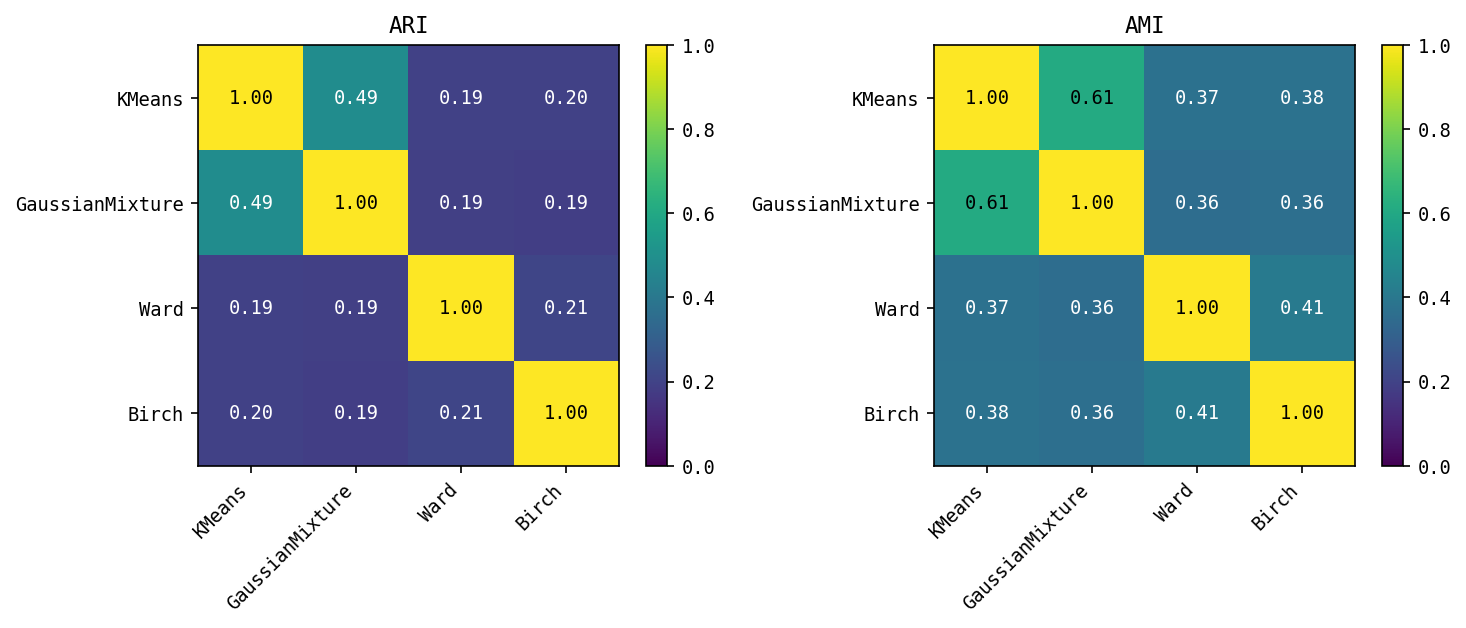

In [64]:
fig,axes = plt.subplots(1,2,figsize=(10,4))
for ax,matrix,title in [(axes[0],ari,'ARI'),(axes[1],ami,'AMI')]:
    image = ax.imshow(matrix,vmin=0,vmax=1,cmap='viridis')
    ax.set_xticks(range(len(names)),names,rotation=45,ha='right')
    ax.set_yticks(range(len(names)),names)
    ax.set_title(title)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j,i,f'{matrix.iloc[i,j]:.2f}',ha='center',va='center',color='white' if matrix.iloc[i,j]<.5 else 'black')
    fig.colorbar(image,ax=ax)
show_figure(fig,'simple_model_membership_agreement')

In [65]:
MODEL_A = 'KMeans'
MODEL_B = 'GaussianMixture'
cluster_overlap = pd.crosstab(model_labels[MODEL_A],model_labels[MODEL_B])
display(cluster_overlap)
display(cluster_overlap.div(cluster_overlap.sum(axis=1),axis=0))

GaussianMixture,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
KMeans,,,,,,,,,,,,,,,,,,
0,0,97,1,1,95,18,34,170,30,106,11,0,0,19,2,1,51,1
1,0,0,0,1651,0,0,7,269,92,2,0,0,0,3,88,0,0,0
2,5,0,0,13,133,0,185,67,36,20,0,0,9,13,417,22,1,73
3,8,4,0,0,18,24,8,0,42,0,1446,0,0,39,0,21,1,0
4,468,0,9,114,42,0,29,86,424,39,90,0,7,445,54,18,6,40
5,3,0,706,0,2,0,0,0,0,0,1,0,6,6,0,37,0,8
6,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0
7,1345,0,32,0,1,0,0,0,1,2,70,0,2,30,4,352,0,11
8,0,9,0,0,26,1009,9,0,0,0,1,0,0,1,0,0,61,0


GaussianMixture,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
KMeans,,,,,,,,,,,,,,,,,,
0,0.000000,0.152276,0.001570,0.001570,0.149137,0.028257,0.053375,0.266876,0.047096,0.166405,0.017268,0.0,0.000000,0.029827,0.003140,0.001570,0.080063,0.001570
1,0.000000,0.000000,0.000000,0.781723,0.000000,0.000000,0.003314,0.127367,0.043561,0.000947,0.000000,0.0,0.000000,0.001420,0.041667,0.000000,0.000000,0.000000
2,0.005030,0.000000,0.000000,0.013078,0.133803,0.000000,0.186117,0.067404,0.036217,0.020121,0.000000,0.0,0.009054,0.013078,0.419517,0.022133,0.001006,0.073441
3,0.004966,0.002483,0.000000,0.000000,0.011173,0.014898,0.004966,0.000000,0.026071,0.000000,0.897579,0.0,0.000000,0.024209,0.000000,0.013035,0.000621,0.000000
4,0.250134,0.000000,0.004810,0.060930,0.022448,0.000000,0.015500,0.045965,0.226617,0.020844,0.048103,0.0,0.003741,0.237841,0.028862,0.009621,0.003207,0.021379
5,0.003901,0.000000,0.918075,0.000000,0.002601,0.000000,0.000000,0.000000,0.000000,0.000000,0.001300,0.0,0.007802,0.007802,0.000000,0.048114,0.000000,0.010403
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,0.727027,0.000000,0.017297,0.000000,0.000541,0.000000,0.000000,0.000000,0.000541,0.001081,0.037838,0.0,0.001081,0.016216,0.002162,0.190270,0.000000,0.005946
8,0.000000,0.008065,0.000000,0.000000,0.023297,0.904122,0.008065,0.000000,0.000000,0.000000,0.000896,0.0,0.000000,0.000896,0.000000,0.000000,0.054659,0.000000


## Select one or two models for the ranking study

Choose from the result and membership tables. A second model should provide a useful contrast rather than duplicate the first model's membership. Two panels per cluster can be a substantial workload; task counts below are the complete bank, not a per-participant requirement.

In [66]:
test_models = ['KMeans']  # optionally add 'GaussianMixture', 'Ward' or 'Birch'
test_plan = model_results.loc[test_models].copy()
test_plan['planned_tasks'] = test_plan.k*TASKS_PER_CLUSTER
test_plan['audio_minutes_one_play'] = test_plan.planned_tasks*(CANDIDATES_PER_TASK+1)*PLANNED_CLIP_SECONDS/60
display(test_plan)

,k,silhouette,CH,DB,distortion,Gini,smallest_cluster,planned_tasks,audio_minutes_one_play
model,,,,,,,,,
KMeans,20,0.011021,473.386651,3.386505,10.175685,0.285288,2,40,40.0


## Build within-cluster ranking tasks

For each cluster, use the available real song nearest its empirical centroid as the reference. Sample two disjoint panels of five candidates spanning within-cluster distance. Record the expected distance order privately and randomize the initial display order. Clusters with too few available songs are listed in the coverage table; no songs are borrowed from other clusters.

File existence does not establish excerpt provenance or playback quality. The listening-test app resolves the track IDs to audio and records the listener's most-to-least-similar order. This task evaluates within-cluster ordering, not cluster separation.

In [67]:
audio_paths = {}
for folder in AUDIO_SEARCH_DIRS:
    for file in (PROJECT_DIR/folder).rglob('*.wav'):
        if file.stem.isdigit(): audio_paths.setdefault(int(file.stem),str(file.resolve()))
print('Available audio track IDs:',len(audio_paths))

Available audio track IDs: 25000


In [68]:
task_rows,coverage = [],[]
rng = np.random.default_rng(SEED)
task_id = 0
ids = np.asarray(catalog_track_ids)
for name in test_models:
    labels = model_labels[name].to_numpy()
    for cluster in np.unique(labels):
        members = np.flatnonzero(labels==cluster)
        centroid = X_catalog[members].mean(axis=0)
        available = members[np.isin(ids[members],list(audio_paths))]
        needed = 1+TASKS_PER_CLUSTER*CANDIDATES_PER_TASK
        if len(available)<needed:
            coverage.append({'model':name,'cluster':int(cluster),'members':len(members),'available':len(available),'tasks':0})
            continue
        center_distance = np.linalg.norm(X_catalog[available]-centroid,axis=1)
        reference = available[np.lexsort((ids[available],center_distance))[0]]
        unused = available[available!=reference]
        for panel in range(TASKS_PER_CLUSTER):
            distance = np.linalg.norm(X_catalog[unused]-X_catalog[reference],axis=1)
            ordered = unused[np.lexsort((ids[unused],distance))]
            chosen = ordered[np.rint(np.linspace(0,len(ordered)-1,CANDIDATES_PER_TASK)).astype(int)]
            display_order = rng.permutation(CANDIDATES_PER_TASK)
            for rank,index in enumerate(chosen):
                task_rows.append({'task_id':task_id,'model':name,'cluster':int(cluster),'panel':panel+1,
                    'reference_track_id':int(ids[reference]),'candidate_track_id':int(ids[index]),
                    'distance':float(np.linalg.norm(X_catalog[index]-X_catalog[reference])),
                    'expected_rank':rank+1,'display_position':int(np.flatnonzero(display_order==rank)[0])+1})
            unused = unused[~np.isin(unused,chosen)]
            task_id += 1
        coverage.append({'model':name,'cluster':int(cluster),'members':len(members),'available':len(available),'tasks':TASKS_PER_CLUSTER})
ranking_tasks = pd.DataFrame(task_rows)
ranking_coverage = pd.DataFrame(coverage)
display(ranking_tasks.head(20))
display(ranking_coverage)

,task_id,model,cluster,panel,reference_track_id,candidate_track_id,distance,expected_rank,display_position
0,0,KMeans,0,1,98301,98300,1.948982,1,5
1,0,KMeans,0,1,98301,75658,3.785311,2,4
2,0,KMeans,0,1,98301,86720,4.335630,3,2
3,0,KMeans,0,1,98301,41983,4.906477,4,3
4,0,KMeans,0,1,98301,10240,11.418676,5,1
5,1,KMeans,0,2,98301,51592,2.805668,1,2
6,1,KMeans,0,2,98301,114408,3.787555,2,3
7,1,KMeans,0,2,98301,45429,4.333369,3,4
8,1,KMeans,0,2,98301,68421,4.904660,4,1
9,1,KMeans,0,2,98301,10239,11.418676,5,5


,model,cluster,members,available,tasks
0,KMeans,0,637,637,2
1,KMeans,1,2112,2112,2
2,KMeans,2,994,994,2
3,KMeans,3,1611,1611,2
4,KMeans,4,1871,1871,2
5,KMeans,5,769,769,2
6,KMeans,6,2,2,0
7,KMeans,7,1850,1850,2
8,KMeans,8,1116,1116,2
9,KMeans,9,1381,1381,2


In [69]:
ranking_dir = RUN_DIR/'simple_ranking_test'
ranking_dir.mkdir(exist_ok=True)
public_tasks = []
if not ranking_tasks.empty:
    task_order = rng.permutation(ranking_tasks.task_id.unique())
    new_ids = {old:int(new+1) for new,old in enumerate(task_order)}
    ranking_tasks['task_id'] = ranking_tasks.task_id.map(new_ids)
    for number in range(1,len(task_order)+1):
        group = ranking_tasks[ranking_tasks.task_id==number].sort_values('display_position')
        public_tasks.append({'task_id':number,'reference_track_id':int(group.reference_track_id.iloc[0]),
                             'candidate_track_ids':group.candidate_track_id.astype(int).tolist()})
ranking_tasks.to_csv(ranking_dir/'ranking_answer_key.csv',index=False)
ranking_coverage.to_csv(ranking_dir/'ranking_coverage.csv',index=False)
with (ranking_dir/'ranking_tasks.json').open('w',encoding='utf8') as f:
    json.dump(public_tasks,f,indent=2)
print('Saved',len(public_tasks),'ranking tasks to',ranking_dir)

Saved 38 ranking tasks to C:\Users\salom\Documents\PHD\music-recommendation-research\outputs\20261026T004854118842Z\simple_ranking_test


## Summary

### Data and feature-selection methods

The analysis used 25,000 FMA medium tracks and 1,064 combined audio descriptors. Development preprocessing removed three empty or constant columns, leaving 1,061 eligible features. Median imputation and Min-Max scaling were fitted on 2,000 development tracks; 1,000 separate tracks were used for confirmation. No genre labels were used in selection or evaluation.

Six unsupervised approaches were compared against the complete feature representation:

1. **Variance ranking:** retain the top-ranked original features by variance after scaling.
2. **Spearman correlation filtering:** greedily remove redundant features using absolute rank correlation.
3. **Hierarchical feature grouping:** group features using average linkage on `1 - abs(Spearman correlation)` and retain the highest-variance representative per group.
4. **PCA-loading ranking:** rank original features by weighted absolute loadings from components covering 90% of development variance. The retained original features do not have a corresponding explained-variance guarantee.
5. **Laplacian Score:** rank features by locality preservation on a symmetric weighted five-neighbor graph.
6. **Chained filtering:** apply Spearman filtering at 0.95, variance filtering at 0.01, and hierarchical grouping at distance 0.30 sequentially.

Ranked methods were evaluated using coarse-to-fine feature-count search. Comparison included reference-neighbor preservation, selection stability, marginal variance, residual correlation, feature origins, runtime, and exact feature-set overlap. Representative subsets were:

| Method | Features | Development neighbor preservation | Selection stability (Jaccard) | Met active selection rule |
|---|---:|---:|---:|---|
| Variance ranking | 788 | 94.22% | 98.41% | Yes |
| PCA-loading ranking | 835 | 94.20% | 98.73% | Yes |
| Laplacian Score | 848 | 87.12% | 98.75% | No |
| Spearman filtering | 821 | 73.16% | 99.19% | No |
| Hierarchical feature grouping | 698 | 73.23% | 98.58% | No |
| Chained filtering | 304 | 61.46% | 95.79% | No |

These are the representative candidates reported by the configured search, not an exhaustive optimum for each method. Feature counts differ; matched-count overlap is examined separately. The complete 1,061-feature baseline preserves its own reference neighborhoods by definition and is excluded by the dimensionality budget.

### Selected representation and confirmation

The preservation-first rule allowed at most 80% of the eligible columns and selected the smallest stable subset within two percentage points of the strongest development preservation under that budget. **Variance ranking selected 788 features: 404 segment-derived and 384 global descriptors**, retaining 74.27% of eligible columns.

On confirmation tracks, the selected subset preserved 93.92% of reference neighbors, compared with 95.81% for the frozen 848-feature variance comparator. The 1.89-percentage-point gap met the configured two-point tolerance and the absolute preservation floor.

The variance and PCA-loading representative subsets shared 770 features (Jaccard 0.903); at the same feature count their Jaccard overlap was 0.910. Their representations were therefore closely related. The 304-feature chained subset was contained in the selected variance subset but did not preserve enough reference neighbors to qualify. Stability alone did not establish adequate preservation.

### Full-catalog clustering

Distortion curves on 5,000 tracks were evaluated for every k from 7 through 40. Kneed selected the cluster counts below. Each selected configuration was fitted on all 25,000 tracks. Silhouette was estimated on 1,000 tracks; CH, DB, distortion, Gini, and assignments used the complete catalog.

| Model | Elbow k | Silhouette | CH | DB | Gini | Smallest cluster |
|---|---:|---:|---:|---:|---:|---:|
| K-Means | 20 | 0.0110 | 473.39 | 3.3865 | 0.2853 | 2 |
| Gaussian mixture | 18 | 0.0072 | 508.35 | 3.4232 | 0.2671 | 2 |
| Ward | 19 | -0.0177 | 366.12 | 4.1246 | 0.3734 | 1 |
| Birch | 20 | -0.0098 | 352.65 | 4.2295 | 0.4135 | 1 |

K-Means had the highest silhouette and lowest DB, while GMM had the highest CH. Ward and Birch had negative silhouette estimates; Birch also exceeded the configured Gini ceiling of 0.40. Low silhouette values indicate limited separation in this representation. K-Means/GMM full-catalog membership agreement was ARI 0.4872, providing a distinct partition contrast rather than identical assignments.

All four models and their track assignments are saved under `models/20261026T004854118842Z/simple_elbow/`. Shared preprocessing is saved separately. The Birch PKL retains prediction data but does not support incremental `partial_fit`.

### Listening-test implications and limitations

K-Means is the primary candidate, with GMM as an optional second contrast. Two panels per cluster would nominally produce 40 K-Means tasks and 36 GMM tasks. With a reference and five candidates per panel, one 10-second play of each presented clip corresponds to 40 or 36 minutes of audio before replay and interaction. The bank should be divided into participant blocks.

Every fitted model contains clusters with only one or two songs. Complete coverage with two disjoint five-candidate panels per cluster is therefore impossible without an explicit coverage policy. Tasks use a central real-song reference and randomized distance-spanning within-cluster candidates; excluded clusters must be reported.

Selection depends on scaling, sampling, search coverage, and exploratory thresholds. Fitting the selected k on the full catalog does not establish that the elbow would be unchanged if its complete curve were estimated on all tracks. Reference-neighbor preservation, feature-set overlap, and internal clustering metrics measure different properties and do not establish listener-perceived similarity. The ranking study evaluates within-cluster ordering separately from cluster separation.